# Bundle Sheath Leakage Analysis
This notebook investigates the effect of Bundle Sheath (BS) leakage on photosynthetic efficiency. It simulates metabolic fluxes under varying degrees of CO2 and O2 leakage from the BS to the Mesophyll, analyzing how this leakage impacts ATP turnover, Quantum Yield, and the optimal photosynthetic strategy.

In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
from cobra.io import read_sbml_model
from cobra import flux_analysis
import sys
from Auxiliary import *
import multiprocessing
import time
import random
from matplotlib import colors
import matplotlib as mpl
from Flux import *
from Visualization import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable

## 1. Model Preparation
Load the C4 metabolic model and apply physiological constraints, including light-dependent maintenance costs.

In [2]:
"""
Read and prepare C4 model
"""

start = time.time()

#Import C4 model
c4_model = read_sbml_model("../Models/c4_model.xml")

#Define the solver
c4_model.solver = "gurobi"


#Set light-dependent ATP maintence costs
def c4_maintenance(c4_model):
    #Constrains for light dependent maintenance costs
    atp_b = c4_model.reactions.get_by_id("[B]_ATPase_tx")
    photon_b = c4_model.reactions.get_by_id("[B]_Photon_tx")
    atp_m = c4_model.reactions.get_by_id("[M]_ATPase_tx")
    photon_m = c4_model.reactions.get_by_id("[M]_Photon_tx")

    const_b = c4_model.problem.Constraint((0.0049 * photon_b.flux_expression + 2.7852) - atp_b.flux_expression, lb=0,
                                          ub=0)
    c4_model.add_cons_vars(const_b)

    const_m = c4_model.problem.Constraint((0.0049 * photon_m.flux_expression + 2.7852) - atp_m.flux_expression, lb=0,
                                          ub=0)
    c4_model.add_cons_vars(const_m)

    
    # ATP/NADPH 3:1 constraints
    const = c4_model.problem.Constraint(c4_model.reactions.get_by_id("[B]_ATPase_tx").flux_expression - 3 * (
            c4_model.reactions.get_by_id("[B]_NADPHoxc_tx").flux_expression + c4_model.reactions.get_by_id(
        "[B]_NADPHoxp_tx").flux_expression + c4_model.reactions.get_by_id("[B]_NADPHoxm_tx").flux_expression), lb=0,
                                        ub=0)
    c4_model.add_cons_vars(const)

    const = c4_model.problem.Constraint(c4_model.reactions.get_by_id("[M]_ATPase_tx").flux_expression - 3 * (
            c4_model.reactions.get_by_id("[M]_NADPHoxc_tx").flux_expression + c4_model.reactions.get_by_id(
        "[M]_NADPHoxp_tx").flux_expression + c4_model.reactions.get_by_id("[M]_NADPHoxm_tx").flux_expression), lb=0,
                                        ub=0)
    c4_model.add_cons_vars(const)


#Add Light dependent maintenance
c4_maintenance(c4_model)

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-20


In [3]:
c4_model.reactions.get_by_id("[B]_Pi_tx")

Reaction identifier,[B]_Pi_tx
Name,Pi_tx
Memory address,0x70edfa9a2cc0
Stoichiometry,--> [B]_Pi_e --> Pi[e]
GPR,
Lower bound,0.0
Upper bound,9999.0


## 2. Simulation Functions
Define the weighted pFBA algorithm and the simulation wrapper that incorporates leakage constraints.

In [4]:
"""
Code necessary to run a  weighted pFBA
"""
from itertools import chain
from typing import TYPE_CHECKING, Callable, Dict, List, Optional, Union
from warnings import warn
from optlang.symbolics import Zero
from cobra.core.solution import get_solution
from cobra.util import solver as sutil
if TYPE_CHECKING:
    from optlang.interface import Objective
    from cobra import Model, Reaction, Solution

def plasmodesmatal_scaling(v_bs_m):
    x = v_bs_m / (1 + v_bs_m)
    y = 9.30 * 2.0625 * (0.6875 - x) / (0.6875 - 0.333333) # penalty, ratio mesophyll–bundle sheath plasmodesmatal frequencies (Danila et al., 2016)
    return y

# Define the main function for performing weighted pFBA
def weighted_pfba(
    model: "Model",
    fraction_of_optimum: float = 1.0,  # Fraction of the optimal solution to maintain
    objective: Union[Dict, "Objective", None] = None,  # Optional custom objective
    reactions: Optional[List["Reaction"]] = None,  # List of reactions to include in the solution
    volume_ratio: float = 1.0,  # Ratio of bundle sheath to mesophyll volume
) -> "Solution":
    """
    Perform weighted parsimonious flux balance analysis (pFBA) on a given metabolic model.

    Args:
        model: The metabolic model to analyze.
        fraction_of_optimum: Fraction of the optimal solution to maintain.
        objective: Optional custom objective for the analysis.
        reactions: List of reactions to include in the solution.
        volume_ratio: Ratio of bundle sheath to mesophyll volume.

    Returns:
        A Solution object containing the flux distribution.
    """
    # Use all reactions if no specific reactions are provided
    reactions = (
        model.reactions if reactions is None else model.reactions.get_by_any(reactions)
    )
    with model as m:
        # Add the weighted pFBA objective to the model
        add_weighted_pfba(m, objective=objective, fraction_of_optimum=fraction_of_optimum, volume_ratio=volume_ratio)
        # Optimize the model to find the solution
        m.slim_optimize(error_value=None)
        # Extract the solution for the specified reactions
        solution = get_solution(m, reactions=reactions)
    return solution

# Define a helper function to add the weighted pFBA objective to the model
def add_weighted_pfba(
    model: "Model",
    objective: Union[Dict, "Objective", None] = None,  # Optional custom objective
    fraction_of_optimum: float = 1.0,  # Fraction of the optimal solution to maintain
    volume_ratio: float = 1.0,  # Ratio of bundle sheath to mesophyll volume
) -> None:
    """
    Add a weighted pFBA objective to the given metabolic model.

    Args:
        model: The metabolic model to modify.
        objective: Optional custom objective for the analysis.
        fraction_of_optimum: Fraction of the optimal solution to maintain.
        volume_ratio: Ratio of bundle sheath to mesophyll volume.

    Raises:
        ValueError: If the model already has a weighted pFBA objective.
    """
    # Set the custom objective if provided
    if objective is not None:
        model.objective = objective

    # Normalize the volume ratios for mesophyll and bundle sheath
    VM_Norm = 1 / (1 + volume_ratio)
    VBS_Norm = volume_ratio / (1 + volume_ratio)

    # Check if the model already has a weighted pFBA objective
    if model.solver.objective.name == "_weighted_pfba_objective":
        raise ValueError("The model already has a weighted pFBA objective.")

    # Fix the current objective as a constraint to maintain a fraction of the optimum
    sutil.fix_objective_as_constraint(model, fraction=fraction_of_optimum)


    # Get the forward and reverse variables for all reactions
    reaction_variables = (
        (rxn.forward_variable, rxn.reverse_variable) for rxn in model.reactions
    )
    variables = chain(*reaction_variables)

    # Create a new objective for minimizing the weighted fluxes
    model.objective = model.problem.Objective(
        Zero, direction="min", sloppy=True, name="_weighted_pfba_objective"
    )

    # Initialize a dictionary to store the objective coefficients
    objective_dict = {}

    # Define lists of uptake and secretion reactions for mesophyll and bundle sheath
    M_Uptakes_List = ['[M]_Ca_tx', '[M]_H2O_tx', '[M]_CO2_tx', '[M]_O2_tx', '[M]_Pi_tx', 
                      '[M]_Mg_tx', '[M]_Nitrate_tx', '[M]_SO4_tx', '[M]_NH4_tx', '[M]_K_tx', 
                      '[M]_unlProtHYPO_c', '[M]_Photon_tx', '[M]_Arabidopsis_biomass_tx', '[M]_Maize_biomass_tx']

    BS_Uptakes_List = ['[B]_Ca_tx', '[B]_H2O_tx', '[B]_CO2_tx', '[B]_O2_tx', '[B]_Pi_tx', 
                       '[B]_Mg_tx', '[B]_Nitrate_tx', '[B]_SO4_tx', '[B]_NH4_tx', '[B]_K_tx', 
                       '[B]_unlProtHYPO_c', '[B]_Photon_tx']

    for v in variables:
        #We exclude the external uptakes, secretion in the form of biomass and exchange reactions from the minimisation
        if str(v) in M_Uptakes_List or str(v) in BS_Uptakes_List:
            pass
        #The new objective coefficient for the mesophyll corresponds to mesophyll volume fraction
        if "[M]" in str(v) and str(v) not in M_Uptakes_List:
            objective_dict[v] = VM_Norm
         #The new objective coefficient for the bundle sheath corresponds to bundle sheath  volume fraction
        elif "[B]" in str(v) and str(v) not in BS_Uptakes_List:
            objective_dict[v] = VBS_Norm
        #The new objective coefficient for the plasmodesmata exchange reactions is scaled according to the volume ratio
        elif "[MB]" in str(v):
            objective_dict[v] = plasmodesmatal_scaling(v_bs_m=volume_ratio)
            
        else:
            pass
    # Set the new objective coefficients in the model
    model.objective.set_linear_coefficients(objective_dict)

In [5]:

#Function to run the parameter scan
def simul(c4_model, carbon = 20, nitrogen = 1000, light = 1000, volume_ratio = 1,
          biomass_objective = "[M]_Arabidopsis_biomass_tx", BS_PSII = True, Rubisco_Ex = False,
          PC_M = 1, PC_BS = 1, sub = True, Vc_Vo = 3, C4_BS = True, M_RUBISCO=True, leakage = None):
    """
        Simulates the metabolic behavior of a C4 photosynthesis model under various conditions.
        Parameters:
        -----------
        c4_model : cobra.Model
            The metabolic model representing the C4 photosynthesis system.
        carbon : float, optional
            Maximum CO2 uptake rate (default is 20).
        nitrogen : float, optional
            Maximum nitrogen uptake rate (default is 1000).
        light : float, optional
            Maximum light uptake rate (default is 1000).
        volume_ratio : float, optional
            Ratio of bundle sheath (BS) to mesophyll (M) cell volumes (default is 1).
        biomass_objective : str, optional
            The reaction ID for the biomass objective function (default is "[M]_Arabidopsis_biomass_tx").
        BS_PSII : bool, optional
            Whether to enable photosystem II activity in bundle sheath cells (default is True).
        Rubisco_Ex : bool, optional
            Whether to enable Rubisco exchange in bundle sheath cells (default is False).
        PC_M : float, optional
            Proportionality constant for mesophyll photon uptake (default is 1).
        PC_BS : float, optional
            Proportionality constant for bundle sheath photon uptake (default is 1).
        sub : bool, optional
            Whether to enable suberisation in bundle sheath cells, blocking O2 transport (default is True).
        Vc_Vo : float or None, optional
            Rubisco carboxylase/oxygenase ratio. If None, defaults to 100% carboxylation (default is 3).
        C4_BS : bool, optional
            Whether to enable Rubisco activity in bundle sheath cells (default is True).
        M_RUBISCO : bool, optional
            Whether to enable Rubisco activity in mesophyll cells (default is True).
        Returns:
        --------
        pandas.DataFrame
            A DataFrame containing the flux distribution of the model under the specified conditions.
            If the solution is infeasible, the DataFrame will contain zeros for all reactions.
        Raises:
        -------
        Exception
            If an invalid biomass objective equation is provided.
        Notes:
        ------
        - The function modifies the input `c4_model` by adding constraints and adjusting reaction bounds.
        - The function uses a weighted parsimonious flux balance analysis (pFBA) to calculate the flux distribution.
        - The function normalizes systemic uptakes and biomass secretion based on the volume ratio.
    """

    with c4_model:
            # Define volume normalization factors for mesophyll and bundle sheath cells
            VM_Norm = 1 / (1 + volume_ratio)
            VBS_Norm = volume_ratio / (1 + volume_ratio)
            # If Vc_Vo is not None, set up constraints for Rubisco carboxylase/oxygenase ratio
            if Vc_Vo != None:
                # Add constraint for mesophyll Rubisco activity
                const = c4_model.problem.Constraint(
                    Vc_Vo * c4_model.reactions.get_by_id("[M]_RXN_961_p").flux_expression - 
                    1 * c4_model.reactions.get_by_id("[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p").flux_expression, lb=0, ub=0)
                c4_model.add_cons_vars(const)

                # Add constraint for bundle sheath Rubisco activity
                const = c4_model.problem.Constraint(
                    Vc_Vo * c4_model.reactions.get_by_id("[B]_RXN_961_p").flux_expression - 
                    1 * c4_model.reactions.get_by_id("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex").flux_expression, lb=0, ub=0)
                c4_model.add_cons_vars(const)
                
                # Update the solver with the new constraints
                c4_model.solver.update()

                # Convert Vc_Vo to percentage for carboxylation
                Vc_Vo = round((Vc_Vo / (Vc_Vo + 1)) * 100, 0)
            else:
                # Default to 100% carboxylation if Vc_Vo is None
                Vc_Vo = 100

            if leakage != None:
                    

                    c4_model.reactions.get_by_id("[MB]_O2_leakage_c").bounds = (-1000, 0)
                    c4_model.reactions.get_by_id("[MB]_CO2_leakage_c").bounds = (-1000, 0)
                    
                    ## Leakage constraints
                    #o2_leak = c4_model.reactions.get_by_id("[MB]_O2_leakage_c")
                    #psii_b = c4_model.reactions.get_by_id("[B]_PSII_RXN_p")

                    #cons = c4_model.problem.Constraint(
                    #    o2_leak.flux_expression - leakage * psii_b.flux_expression,
                    #    ub=0
                    #)

                    #c4_model.add_cons_vars(cons)
                    
                    #Canonical Decarboxylation reactions
                    CO2_leak = c4_model.reactions.get_by_id("[MB]_CO2_leakage_c")
                    CO2_transport = c4_model.reactions.get_by_id("[MB]_CO2_c")
                    Gly_Decarbox = c4_model.reactions.get_by_id("[B]_GCVMULTI_RXN_m")
                    PEP_CK = c4_model.reactions.get_by_id("[B]_PEPCARBOXYKIN_RXN_c")
                    NAD_ME = c4_model.reactions.get_by_id("[B]_1_PERIOD_1_PERIOD_1_PERIOD_39_RXN_m")
                    NADP_ME = c4_model.reactions.get_by_id("[B]_MALIC_NADP_RXN_p")

                    # ---------- Plastid (_p) decarboxylations (BS) ----------
                    DIAMINOPIMDECARB_p   = c4_model.reactions.get_by_id("[B]_DIAMINOPIMDECARB_RXN_p")
                    IGPSYN_p             = c4_model.reactions.get_by_id("[B]_IGPSYN_RXN_p")
                    RXN_9652_p           = c4_model.reactions.get_by_id("[B]_RXN_9652_p")
                    ACETOOHBUTSYN_p      = c4_model.reactions.get_by_id("[B]_ACETOOHBUTSYN_RXN_p")
                    RXN_9650_p           = c4_model.reactions.get_by_id("[B]_RXN_9650_p")
                    RXN_5682_p           = c4_model.reactions.get_by_id("[B]_RXN_5682_p")
                    KASIII_2_3_1_180_p   = c4_model.reactions.get_by_id("[B]_2_PERIOD_3_PERIOD_1_PERIOD_180_RXN_p")
                    RXN_9654_p           = c4_model.reactions.get_by_id("[B]_RXN_9654_p")
                    PYRUVDEH_p           = c4_model.reactions.get_by_id("[B]_PYRUVDEH_RXN_p")        # plastid PDH
                    RXN_9653_p           = c4_model.reactions.get_by_id("[B]_RXN_9653_p")
                    RXN_7800_p           = c4_model.reactions.get_by_id("[B]_RXN_7800_p")
                    RXN_9651_p           = c4_model.reactions.get_by_id("[B]_RXN_9651_p")
                    RXN_9648_p           = c4_model.reactions.get_by_id("[B]_RXN_9648_p")
                    ACETOLACTSYN_p       = c4_model.reactions.get_by_id("[B]_ACETOLACTSYN_RXN_p")

                    # ---------- Cytosolic (_c) decarboxylations ----------
                    ISOCITDEH_c          = c4_model.reactions.get_by_id("[B]_ISOCITDEH_RXN_c")

                    # ---------- Mitochondrial (_m) decarboxylations ----------
                    PYRUVDEH_m           = c4_model.reactions.get_by_id("[B]_PYRUVDEH_RXN_m")     # mito PDH


                    const = c4_model.problem.Constraint(
                        CO2_leak.flux_expression + VBS_Norm * leakage * (ISOCITDEH_c.flux_expression + ACETOLACTSYN_p.flux_expression + RXN_9648_p.flux_expression + 
                                                                         RXN_9651_p.flux_expression + RXN_7800_p.flux_expression + RXN_9653_p.flux_expression +
                                                                         PYRUVDEH_p.flux_expression + RXN_9654_p.flux_expression + KASIII_2_3_1_180_p.flux_expression + RXN_5682_p.flux_expression + 
                                                                         RXN_9650_p.flux_expression + ACETOOHBUTSYN_p.flux_expression + RXN_9652_p.flux_expression + 
                                                                         IGPSYN_p.flux_expression + DIAMINOPIMDECARB_p.flux_expression + PYRUVDEH_m.flux_expression +
                    Gly_Decarbox.flux_expression + PEP_CK.flux_expression + NAD_ME.flux_expression + NADP_ME.flux_expression + CO2_transport.flux_expression),
                        lb=0, ub=0
                    )
                    c4_model.add_cons_vars(const)
            else:
                c4_model.reactions.get_by_id("[MB]_O2_leakage_c").bounds = (0, 0)
                c4_model.reactions.get_by_id("[MB]_CO2_leakage_c").bounds = (0, 0)

            # Set the biomass objective equation and block other biomass-related reactions
            #c4_model.reactions.get_by_id("[M]_Biomass_tx").bounds = (0, 0)
            #c4_model.reactions.get_by_id("[B]_Biomass_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[M]_AraCore_Biomass_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[B]_AraCore_Biomass_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[M]_Phloem_output_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[B]_Phloem_output_tx").bounds = (0, 0)

            # Configure the biomass objective based on the input parameter
            if biomass_objective == "[M]_Arabidopsis_biomass_tx":
                c4_model.reactions.get_by_id("[M]_Arabidopsis_biomass_tx").bounds = (0, 1000)
                c4_model.reactions.get_by_id("[B]_Arabidopsis_biomass_tx").bounds = (0, 0)
            
            else:
                # Raise an exception if an invalid biomass objective is provided
                raise Exception("Please insert a valid biomass equation")
            
            # Set the objective function to the selected biomass reaction
            c4_model.objective = c4_model.reactions.get_by_id(biomass_objective)
            
            # Enable or disable photosystem II activity in bundle sheath cells
            if BS_PSII == True:
                set_bounds('[B]_PSII_RXN_p', (0, 999999), c4_model)
            else:
                set_bounds('[B]_PSII_RXN_p', (0, 0), c4_model)

            # Enable or disable Rubisco activity in bundle sheath cells
            if C4_BS == True:
                set_bounds('[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 1000), c4_model)
            else:
                set_bounds('[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 0), c4_model)

            # Enable or disable Rubisco activity in mesophyll cells
            if M_RUBISCO == True:
                set_bounds('[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 1000), c4_model)
            else:
                set_bounds('[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 0), c4_model)

            # Enable or disable suberisation in bundle sheath cells
            if sub == True:
                # Block O2 transport between cell types
                set_bounds("[MB]_OXYGEN_MOLECULE_c", (0, 0), c4_model)
                set_bounds("[MB]_SUPER_OXIDE_c", (0, 0), c4_model)
                set_bounds("[MB]_CO2_c", (0, 0), c4_model)
            else:
                # Allow O2 transport between cell types
                set_bounds("[MB]_OXYGEN_MOLECULE_c", (-999999, 999999), c4_model)
                set_bounds("[MB]_SUPER_OXIDE_c", (-999999, 999999), c4_model)
                set_bounds("[MB]_CO2_c", (-999999, 999999), c4_model)
       
            # Enable or disable Rubisco exchange in bundle sheath cells
            if Rubisco_Ex == True:
                set_bounds("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex", (0, 1000), c4_model)
            else:
                set_bounds("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex", (0, 0), c4_model)

            # Set maximum CO2 and nitrogen uptake rates in the medium
            medium = c4_model.medium
            medium["[M]_CO2_tx"] = carbon  # CO2 uptake constraint
            medium["[B]_Nitrate_tx"] = nitrogen  # Nitrogen uptake constraint
            medium["[B]_O2_tx"] = 0  # Block O2 uptake in bundle sheath cells
            medium["[B]_CO2_tx"] = 0  # Block CO2 uptake in bundle sheath cells
            c4_model.medium = medium
            
            # Normalize exchange reactions between mesophyll and bundle sheath cells
            for reaction in c4_model.reactions:
                if reaction.id[0:4] == "[MB]":
                    dict = {reaction.products[0]: -(1 / VBS_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
                    dict = {reaction.reactants[0]: (1 / VM_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
            
            # Set light uptake constraints for mesophyll and bundle sheath cells
            set_bounds("[M]_Photon_tx", (0, light * PC_M), c4_model)
            set_bounds("[B]_Photon_tx", (0, light * PC_BS), c4_model)
            
            #Block Mannitol Transport
            set_bounds("[MB]_MANNITOL_1P_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNITOL_c", (0, 0), c4_model)

            #Block Excchange of Alternative Triose Phosphates and Phosphoglycollate
            set_bounds("[MB]_DIHYDROXY_ACETONE_PHOSPHATE_c", (0, 0), c4_model)
            set_bounds("[MB]_2_PG_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNOSE_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNOSE_6P_c", (0, 0), c4_model)
            set_bounds("[MB]_FUM_c", (0, 0), c4_model)

            #Block Glycollate transport
            set_bounds("[MB]_GLYCOLLATE_c", (0, 0), c4_model)
            set_bounds("[MB]_2_KETOGLUTARATE_c", (0, 0), c4_model)

            #Block Phosphate transport
            set_bounds("[MB]_Pi_c", (-1000, 1000), c4_model)
            set_bounds("[MB]_aPi_c", (-1000, 1000), c4_model)

            #Block Proton Uptake 
            set_bounds("[B]_H_tx", (0, 0), c4_model)
            set_bounds("[M]_H_tx", (0, 0), c4_model)

            #Block glucose 1 P and Heteroglycan Transport
            set_bounds("[MB]_GLC_1_P_c", (0, 0), c4_model)
            set_bounds("[MB]_Heteroglycans_c", (0, 0), c4_model)


            # Normalize systemic uptakes into mesophyll and bundle sheath cells
            M_Uptakes_List = ['[M]_Ca_tx', '[M]_H2O_tx', '[M]_CO2_tx', '[M]_O2_tx', '[M]_Pi_tx', 
                              '[M]_Mg_tx', '[M]_Nitrate_tx', '[M]_SO4_tx', '[M]_NH4_tx', '[M]_K_tx', '[M]_unlProtHYPO_c']
            
            BS_Uptakes_List = ['[B]_Ca_tx', '[B]_H2O_tx', '[B]_CO2_tx', '[B]_O2_tx', '[B]_Pi_tx', 
                              '[B]_Mg_tx', '[B]_Nitrate_tx', '[B]_SO4_tx', '[B]_NH4_tx', '[B]_K_tx', '[B]_unlProtHYPO_c']
        
            for reaction in c4_model.reactions:
                if reaction.id in M_Uptakes_List:
                    dict = {reaction.products[0]: -(1 / VM_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
                elif reaction.id in BS_Uptakes_List:
                    dict = {reaction.products[0]: -(1 / VBS_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)

            # Normalize biomass secretion for mesophyll cells
            M_biomass_List = ["[M]_Arabidopsis_biomass_tx", "[M]_Maize_biomass_tx"]

            dict_comb = {}

            for reaction in c4_model.reactions:
                if reaction.id in M_biomass_List:
                    for index in range(len(reaction.reactants)):
                        dictionary = {reaction.reactants[index]: -((reaction.get_coefficient(reaction.reactants[index]) / VM_Norm))}
                        dict_comb.update(dictionary)
                    reaction.subtract_metabolites(dict_comb, combine=False)

            # Run weighted parsimonious flux balance analysis (pFBA)
            try:
                solution = weighted_pfba(model=c4_model, volume_ratio=volume_ratio)  
                solution_frame = solution.to_frame()
                solution_frame.rename(columns={"fluxes": "{}_{}_{}_{}_{}_{}_{}_{}".format(light, volume_ratio, PC_M, PC_BS, Vc_Vo, carbon, nitrogen, leakage)}, inplace=True)
            
            # Handle unfeasible flux solutions
            except:
                solution = {"{}_{}_{}_{}_{}_{}_{}_{}".format(light, volume_ratio, PC_M, PC_BS, Vc_Vo, carbon, nitrogen, leakage): [0] * len(c4_model.reactions)}

                # Unfeasible solutions will have 0s in place of parameters
                reaction_index = [reaction.id for reaction in c4_model.reactions]
                solution_frame = pd.DataFrame(solution, index=reaction_index)
                
            # Return the solution as a DataFrame
            return solution_frame.iloc[:, 0].to_frame()


## 3. Parameter Scans
Run simulations across a range of $V_{BS/M}$ ratios, photorespiratory conditions ($V_c/V_o$), and leakage percentages.

In [6]:
#List of parameters for parameter scan

#List of V_BS/M ratios
v_ratio_list = [0.1, 0.5, 1, 1.5, 2]

#Leakage values (fraction of flux leaking back)
leakage_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
#leakage_list = np.linspace(0.1, 1.0, 60) #fine_grain

#List of PPFDs (light intensities)
light_list = [1000]

#List of A (maximum carbon assimilation)
carbon_list = [20]

#List of maximum nitrate assimilation
nitrogen_list = [1000]  

#List of photorespiratory ratios ((Vc/(Vc+Vo)) * 100)
Photoresp_ratio_list = [50, 55, 60, 65, 70, 75, 80, 85, 90, 95, None]
#Photoresp_ratio_list = list(np.arange(50, 95, 1)) + [None] #fine_grain

#List of mesophyll photosynthetic capacity %s
PC_M_list = [1]

#List of bundle sheath photosynthetic capacity %s
PC_BS_list = [1]


def model_scan(model, carbon_list, nitrogen_list, light_list, v_ratio_list, PC_M, PC_BS, Photoresp_ratio_list,
               biomass_equation, PSII = True, BS_Rubisco = False, csv_filename = "20_PSII.csv", suberisation = True, BS_C4 = True, Mesophyll_Rubisco = True,
               leakage = None):
    """
    Perform a parameter scan for a given C4 photosynthesis model using multiprocessing.
    This function generates combinations of input parameters, runs simulations in parallel
    using these combinations, and aggregates the results into a single DataFrame.
    Args:
        model (object): The C4 photosynthesis model to be simulated.
        carbon_list (list): List of carbon uptake values to be tested.
        nitrogen_list (list): List of nitrogen uptake values to be tested.
        light_list (list): List of light intensity values to be tested.
        v_ratio_list (list): List of volume ratio values to be tested.
        PC_M (list): List of mesophyll phosphoenolpyruvate carboxylase (PEPC) values.
        PC_BS (list): List of bundle sheath phosphoenolpyruvate carboxylase (PEPC) values.
        Photoresp_ratio_list (list): List of photorespiratory ratios (as percentages) to be tested.
        biomass_equation (callable): String representing the biomass objective.
        PSII (bool, optional): Whether PSII is active in the bundle sheath. Defaults to True.
        BS_Rubisco (bool, optional): Whether Rubisco is exclusively in the bundle sheath. Defaults to False.
        csv_filename (str, optional): Filename for saving results (not used in this function). Defaults to "20_PSII.csv".
        suberisation (bool, optional): Whether suberisation is considered in the model. Defaults to True.
        BS_C4 (bool, optional): Whether C4 metabolism is active in the bundle sheath. Defaults to True.
        Mesophyll_Rubisco (bool, optional): Whether Rubisco is active in the mesophyll. Defaults to True.
    Returns:
        pd.DataFrame: A DataFrame containing the aggregated results of the parameter scan.
    Notes:
        - The function uses all available CPU cores for parallel processing.
        - The photorespiratory ratios are converted from percentages to Vc:Vo ratios internally.
        - The `simul` function is used to run the simulations.
    """
    
    #Converting photorespiratory ratio from percentage to x:1 (Vc:Vo) ratios
    photo_ratio = []
    for ratio in Photoresp_ratio_list:
        if ratio != None:
            value = -(ratio/(ratio-100))
            photo_ratio.append(value)
        else:
            photo_ratio.append(ratio)

    appended_dataframes = []
    
    global run_simulation
    
    def run_simulation(parameters):

    #Calling existing simulation function with the given parameters
        return simul(c4_model = model, carbon = parameters[5], nitrogen = parameters[6], light = parameters[1], 
                    volume_ratio = parameters[0], biomass_objective = biomass_equation, BS_PSII = PSII, Rubisco_Ex = BS_Rubisco,
                    PC_M = parameters[2], PC_BS = parameters[3], sub=suberisation, Vc_Vo= parameters[4], C4_BS=BS_C4, M_RUBISCO = Mesophyll_Rubisco, leakage=parameters[7])

    # Create a list of parameter combinations
    all_parameters = [(v_ratio, light_value, PC_M_value, PC_BS_value, resp_ratio, c_uptake, n_uptake, leakage) for v_ratio in v_ratio_list for light_value in light_list for PC_M_value in PC_M for PC_BS_value in PC_BS for resp_ratio in photo_ratio for c_uptake in carbon_list for n_uptake in nitrogen_list for leakage in leakage_list]

    appended_dataframes = []

    if __name__ == '__main__':
        # Number of processes to use - using all CPUs
        num_processes = multiprocessing.cpu_count()

        # Create a pool of worker processes
        with multiprocessing.Pool(processes=num_processes) as pool:
            # Use map to distribute the parameter combinations to worker processes
            results = pool.map(run_simulation, all_parameters)
            appended_dataframes.extend(results)

    #Merging the resulting Datasets
    parameter_scan_df = pd.concat(appended_dataframes, axis=1)

    #Checking Dataframes for consistency
    return parameter_scan_df

In [7]:
# --- C3 Scenario Scan ---
data_C3 = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = False, Mesophyll_Rubisco = True,
                                suberisation = False, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = False, leakage = None)


In [8]:
# --- C4 Scenario Scan (with Leakage) ---
data_C4 = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = True, Mesophyll_Rubisco = False,
                                suberisation = True, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = leakage_list)

In [9]:
# --- Variable Scenario Scan (with Leakage) ---
data_variable = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = True, Mesophyll_Rubisco = True,
                                suberisation = False, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = leakage_list)

In [10]:
end = time.time()

print("The analysis lasted {} minutes".format((end-start)/60))

The analysis lasted 0.5123323480288188 minutes


## 4. Data Processing
Structure the raw simulation data into DataFrames suitable for analysis, calculating derived metrics like Quantum Yield and ATP turnover.

In [11]:
def structure_data_leakage(df: pd.DataFrame, model, filename: Optional[str] = None) -> pd.DataFrame:
    """
    Build the summary DataFrame from `df`. If `filename` is provided and points to a readable CSV,
    it is returned immediately; otherwise the summary is built and optionally saved to `filename`.
    """
    def _read_if_exists(fname):
        if fname is None:
            return None
        try:
            return pd.read_csv(fname, index_col=0)
        except Exception:
            return None

    def _prepare_indexed_copy(df_in: pd.DataFrame) -> pd.DataFrame:
        dfc = df_in.copy()
        if "Unnamed: 0" in dfc.columns:
            dfc = dfc.set_index("Unnamed: 0")
        return dfc

    def _parse_column_metadata(cols):
        parts = [col.split("_") for col in cols]
        def safe_get(p, i, cast, default=np.nan):
            try:
                return cast(p[i])
            except Exception:
                return default
        light = [safe_get(p, 0, int) for p in parts]
        volume = [safe_get(p, 1, float) for p in parts]
        pc_m = [safe_get(p, 2, float) for p in parts]
        pc_bs = [safe_get(p, 3, float) for p in parts]
        photoresp = [safe_get(p, 4, float) for p in parts]
        max_c = [safe_get(p, 5, float) for p in parts]
        max_n = [safe_get(p, 6, float) for p in parts]
        leakage_token = [p[7] if len(p) > 7 else None for p in parts]
        return light, volume, pc_m, pc_bs, photoresp, max_c, max_n, leakage_token

    def _get_series_rounded(index_label, cols, decimals=1):
        if index_label not in df_copy.index:
            return [np.nan] * len(cols)
        return [round(df_copy.at[index_label, col], decimals) for col in cols]

    def scale(x, in_min, in_max, out_min, out_max):
        return (x - in_min) / (in_max - in_min) * (out_max - out_min) + out_min

    existing = _read_if_exists(filename)
    if existing is not None:
        return existing

    df_copy = _prepare_indexed_copy(df)
    cols = list(df_copy.columns)

    (light_max,
     volume_BS_M,
     PC_M_values,
     PC_BS_values,
     photoresp_ratio_values,
     maximum_carbon_assimilation,
     maximum_nitrogen_assimilation,
     leakage_tokens) = _parse_column_metadata(cols)

    # convert leakage token to percentage:
    # - if token is None or "None" (case-insensitive) -> treat as 0.0%
    # - if token is numeric string -> float(token) * 100
    # - if token malformed -> np.nan
    leakage_percent = []
    for tok in leakage_tokens:
        if tok is None:
            leakage_percent.append(0.0)
        elif isinstance(tok, str) and tok.lower() == "none":
            leakage_percent.append(0.0)
        else:
            try:
                leakage_percent.append(round(float(tok) * 100.0, 1))
            except Exception:
                leakage_percent.append(np.nan)

    light_mesophyll = _get_series_rounded("[M]_Photon_tx", cols, 1)
    light_bundle_sheath = _get_series_rounded("[B]_Photon_tx", cols, 1)
    carbon_uptakes = _get_series_rounded("[M]_CO2_tx", cols, 1)
    nitrogen_uptakes = _get_series_rounded("[B]_Nitrate_tx", cols, 1)
    biomass = _get_series_rounded("[M]_Arabidopsis_biomass_tx", cols, 4)

    Rubisco_M_list = _get_series_rounded("[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p", cols, 1)
    Rubisco_BS_C4_list = _get_series_rounded("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p", cols, 1)
    Rubisco_BS_C3_list = _get_series_rounded("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex", cols, 1)
    PEP_CK_list = _get_series_rounded("[B]_PEPCARBOXYKIN_RXN_c", cols, 1)
    NAD_ME_list = _get_series_rounded("[B]_1_PERIOD_1_PERIOD_1_PERIOD_39_RXN_m", cols, 1)
    NADP_ME_list = _get_series_rounded("[B]_MALIC_NADP_RXN_p", cols, 1)
    GLY_DECARBOX_list = _get_series_rounded("[B]_GCVMULTI_RXN_m", cols, 1)
    M_Oxygenase_list = _get_series_rounded("[M]_RXN_961_p", cols, 1)
    BS_Oxygenase_list = _get_series_rounded("[B]_RXN_961_p", cols, 1)

    photo_classification = photosynthetic_classification(df_copy)

    in_min, in_max = 0.1, 2
    out_min, out_max = 10, 1
    VM_Norm = [1 / (1 + v) for v in volume_BS_M]
    VBS_Norm = [v / (1 + v) for v in volume_BS_M]
    scaled_V_BS_M = [scale(v, in_min, in_max, out_min, out_max) for v in volume_BS_M]

    m, bs, t = get_sof(df_copy)
    cet, let = get_CET_LET(df_solutions=df_copy, c4_model=model)
    psi, psii = get_PSI_PSII(df_solutions=df_copy, c4_model=model)
    ATP_turnover_M, ATP_turnover_BS = ATP_Production(df=df_copy, model=model)

    NADPH_turnover_M = _get_series_rounded("[M]_1_PERIOD_18_PERIOD_1_PERIOD_2_RXN_p", cols, 1)
    NADPH_turnover_BS = _get_series_rounded("[B]_1_PERIOD_18_PERIOD_1_PERIOD_2_RXN_p", cols, 1)

    rows = list(zip(
        photoresp_ratio_values,
        light_max,
        volume_BS_M,
        maximum_nitrogen_assimilation,
        maximum_carbon_assimilation,
        carbon_uptakes,
        nitrogen_uptakes,
        np.array(light_mesophyll) * VM_Norm,
        np.array(light_bundle_sheath) * VBS_Norm,
        PC_M_values,
        PC_BS_values,
        np.array(m) * VM_Norm,
        np.array(bs) * VBS_Norm,
        np.array(t) * scaled_V_BS_M,
        photo_classification,
        biomass,
        np.array(ATP_turnover_BS) * VBS_Norm,
        np.array(ATP_turnover_M) * VM_Norm,
        NADPH_turnover_M,
        NADPH_turnover_BS,
        Rubisco_M_list,
        Rubisco_BS_C3_list,
        Rubisco_BS_C4_list,
        GLY_DECARBOX_list,
        PEP_CK_list,
        NADP_ME_list,
        NAD_ME_list,
        np.array(cet) * VBS_Norm,
        np.array(let) * VBS_Norm,
        np.array(psi) * VBS_Norm,
        np.array(psii) * VBS_Norm,
        BS_Oxygenase_list,
        M_Oxygenase_list,
        leakage_percent
    ))

    columns = [
        "Vc_Vo", "PPFD", "V_BS_M", "Maximum Nitrogen Uptake", "Maximum Carbon Uptake",
        "Carbon Uptake", "Nitrogen Uptake", "Light Mesophyll", "Light Bundle Sheath",
        "PC_M", "PC_BS", "SoF M", "SoF BS", "SoF transport", "Photosynthesis", "Biomass",
        "ATP BS", "ATP M", "NADPH BS", "NADPH M", "M_Rubisco", "BS_Rubisco",
        "BS_Rubisco_C4", "Glycine Decarboxylase", "PEP-CK", "NADP-ME", "NAD-ME",
        "BS CET", "BS LET", "BS PSI", "BS PSII", "BS Oxygenase", "M Oxygenase",
        "Leakage (%)"
    ]

    result = pd.DataFrame(rows, columns=columns)

    # optionally save
    if filename is not None:
        result.to_csv(filename)

    return result

In [12]:
structured_variable_leakage = structure_data_leakage(data_variable, c4_model)

#structured_variable_leakage.to_csv("../Datasets/structured_variable_leakage_fine_grained_2.csv")

In [13]:
structured_C3_leakage = structure_data_leakage(data_C3, c4_model)

#structured_C3_leakage.to_csv("../Datasets/structured_C3_leakage_fine_grained_2.csv")

In [14]:
structured_C4_leakage = structure_data_leakage(data_C4, c4_model)

#structured_C4_leakage.to_csv("../Datasets/structured_C4_leakage_fine_grained_2.csv")

## 5. Visualization: ATP Turnover 
Compare ATP turnover between C3, C4, and Intermediate scenarios across leakage and photorespiration gradients.

In [15]:
def heatmap_and_summary_noagg(
        df_c3, df_var, df_c4,
        v_ratio,
        leakage_col="Leakage (%)", vcv_col="Vc_Vo",
        atp_m_col="ATP M", atp_bs_col="ATP BS",
        photosyn_col="Photosynthesis",
        v_ratio_col="V_BS_M",
        mode="both", tol=1e-8,
        figsize=(10, 6), show_plot=True,
        annot_fmt="{:.1f}%", annot_fontsize=10,
        print_table=True,
        vmin_intermediate=None, vmax_intermediate=None,
        vmin_c3=None, vmax_c3=None,
        vmin_c4=None, vmax_c4=None):
    """
    Build annotated heatmap with three different color gradients showing ATP reduction (%)
    for intermediate, C3, and C4 scenarios in a single plot.
    
    Parameters:
      vmin_intermediate, vmax_intermediate : float, optional
          Lower and upper bounds for the color scale of Intermediate ATP percentage reduction.
      vmin_c3, vmax_c3 : float, optional
          Lower and upper bounds for the color scale of C3 ATP percentage reduction.
      vmin_c4, vmax_c4 : float, optional
          Lower and upper bounds for the color scale of C4 ATP percentage reduction.
          If None, uses the data range for each scenario.
    """

    def select_vratio(df):
        if v_ratio_col not in df.columns:
            raise KeyError(f"'{v_ratio_col}' not found in dataframe")
        
        sub = df[np.isclose(df[v_ratio_col].astype(float), float(v_ratio), atol=tol)].copy()
        
        if leakage_col in sub.columns:
            sub = sub[~sub[leakage_col].isin([90, 100])]
            
        return sub

    df_c3_sel = select_vratio(df_c3)
    df_c4_sel = select_vratio(df_c4)
    df_var_sel = select_vratio(df_var)

    for name, df in (("C3", df_c3_sel), ("VAR", df_var_sel), ("C4", df_c4_sel)):
        if atp_m_col not in df.columns or atp_bs_col not in df.columns:
            raise KeyError(f"ATP columns '{atp_m_col}' or '{atp_bs_col}' missing in {name} dataset")
        df["_ATP_turn"] = df[atp_m_col].astype(float) + df[atp_bs_col].astype(float)

    # Restrict variable dataset to the intermediate classes
    if photosyn_col not in df_var_sel.columns:
        raise KeyError(f"'{photosyn_col}' not in variable dataset")
    allowed = {"C3_C4_Type_I", "C3_C4_Type_II"}
    df_var_inter = df_var_sel[df_var_sel[photosyn_col].astype(str).isin(allowed)].copy()

    def mapping_from_df(df, df_name):
        if df.empty:
            return {}
        for col in (leakage_col, vcv_col):
            if col not in df.columns:
                raise KeyError(f"'{col}' missing from {df_name}")
        keys = list(zip(df[leakage_col].astype(float), df[vcv_col].astype(float)))
        dupes = [k for k, c in Counter(keys).items() if c > 1]
        if dupes:
            raise ValueError(f"Dataset '{df_name}' contains duplicate (Leakage, Vc_Vo) pairs: {dupes}. "
                             "This function assumes unique pairs (no aggregation).")
        return {k: float(v) for k, v in zip(keys, df["_ATP_turn"].values)}

    map_c3 = mapping_from_df(df_c3_sel, "C3")
    map_c4 = mapping_from_df(df_c4_sel, "C4")
    map_var = mapping_from_df(df_var_inter, "Variable (C3-C4 intermediates)")

    all_keys = sorted(set(list(map_c3.keys()) + list(map_c4.keys()) + list(map_var.keys())),
                      key=lambda x: (x[1], x[0]))
    if not all_keys:
        raise ValueError(f"No (Leakage, Vc_Vo) pairs found in the filtered datasets for V_BS_M={v_ratio}")

    leaks = sorted({k[0] for k in all_keys})
    vcvs = sorted({k[1] for k in all_keys})

    grid_c3 = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)
    grid_c4 = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)
    grid_var = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)

    for (l, v) in all_keys:
        grid_c3.at[v, l] = map_c3.get((l, v), np.nan)
        grid_c4.at[v, l] = map_c4.get((l, v), np.nan)
        grid_var.at[v, l] = map_var.get((l, v), np.nan)

    rows = []
    for (leak, vcv) in sorted({(k[0], k[1]) for k in all_keys}, key=lambda x: (x[1], x[0])):
        atp_var = grid_var.at[vcv, leak]
        atp_c3 = grid_c3.at[vcv, leak]
        atp_c4 = grid_c4.at[vcv, leak]

        # Collect available scenarios (exclude NaNs)
        vals = {}
        if not (atp_var is None or (isinstance(atp_var, float) and np.isnan(atp_var))):
            vals["Intermediate"] = float(atp_var)
        if not (atp_c3 is None or (isinstance(atp_c3, float) and np.isnan(atp_c3))):
            vals["C3"] = float(atp_c3)
        if not (atp_c4 is None or (isinstance(atp_c4, float) and np.isnan(atp_c4))):
            vals["C4"] = float(atp_c4)

        if len(vals) == 0:
            best = None
            pct_diff_closest = np.nan
        else:
            min_val = min(vals.values())
            best_scenarios = [k for k, vv in vals.items() if vv == min_val]
            best = "|".join(best_scenarios)

            other_vals = [vv for k, vv in vals.items() if vv != min_val]
            if len(other_vals) == 0:
                pct_diff_closest = 0.0 if len(best_scenarios) > 1 else np.nan
            else:
                min_other = min(other_vals)
                if np.isclose(min_other, 0.0):
                    pct_diff_closest = np.nan
                else:
                    pct_diff_closest = round((min_other - min_val) / min_other * 100.0, 1)

        rows.append({
            vcv_col: vcv,
            leakage_col: leak,
            "ATP_var": atp_var,
            "ATP_C3": atp_c3,
            "ATP_C4": atp_c4,
            "Best_scenario": best,
            "Pct_diff_closest (%)": pct_diff_closest
        })

    summary_df = pd.DataFrame(rows, columns=[vcv_col, leakage_col, "ATP_var", "ATP_C3", "ATP_C4", "Best_scenario", "Pct_diff_closest (%)"])
    summary_df = summary_df.sort_values([vcv_col, leakage_col], ascending=[True, True]).reset_index(drop=True)

    # Plot heatmap ---
    if show_plot:
        fig, ax = plt.subplots(figsize=figsize)
        
        # Determine vmin/vmax for each scenario
        intermediate_pcts = summary_df[summary_df["Best_scenario"].str.contains("Intermediate", na=False)]["Pct_diff_closest (%)"].dropna()
        c3_pcts = summary_df[summary_df["Best_scenario"] == "C3"]["Pct_diff_closest (%)"].dropna()
        c4_pcts = summary_df[summary_df["Best_scenario"] == "C4"]["Pct_diff_closest (%)"].dropna()
        
        def safe_min_max(series, default_min=0, default_max=10):
            if len(series) == 0:
                return default_min, default_max
            return series.min(), series.max()

        i_min, i_max = safe_min_max(intermediate_pcts)
        c3_min, c3_max = safe_min_max(c3_pcts)
        c4_min, c4_max = safe_min_max(c4_pcts)
        
        if vmin_intermediate is None:
            vmin_intermediate = i_min
        if vmax_intermediate is None:
            vmax_intermediate = i_max
            
        if vmin_c3 is None:
            vmin_c3 = c3_min
        if vmax_c3 is None:
            vmax_c3 = c3_max
            
        if vmin_c4 is None:
            vmin_c4 = c4_min
        if vmax_c4 is None:
            vmax_c4 = c4_max
        
        cmap_intermediate = LinearSegmentedColormap.from_list("intermediate", ["#ffffff", "#e6954dff"])
        cmap_c3 = LinearSegmentedColormap.from_list("c3", ["#ffffff", "#64a4ceff"])
        cmap_c4 = LinearSegmentedColormap.from_list("c4", ["#ffffff", "#6bc56bff"])
        
        # Plot each cell individually based on best scenario
        for _, row in summary_df.iterrows():
            vcv_val = row[vcv_col]
            leak_val = row[leakage_col]
            best_scenario = row["Best_scenario"]
            pct_diff = row["Pct_diff_closest (%)"]
            
            if pd.isna(pct_diff) or best_scenario is None:
                continue
            
            if vcv_val in vcvs and leak_val in leaks:
                i = vcvs.index(vcv_val)
                j = leaks.index(leak_val)
                
                # Select vmin/vmax and colormap based on best scenario
                if "Intermediate" in best_scenario:
                    vmin_use = vmin_intermediate
                    vmax_use = vmax_intermediate
                    cmap_use = cmap_intermediate
                elif best_scenario == "C3":
                    vmin_use = vmin_c3
                    vmax_use = vmax_c3
                    cmap_use = cmap_c3
                elif best_scenario == "C4":
                    vmin_use = vmin_c4
                    vmax_use = vmax_c4
                    cmap_use = cmap_c4
                else:
                    color = 'white'
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, 
                                              facecolor=color, 
                                              edgecolor='lightgray', linewidth=0.5))
                    continue
                
                norm_pct = (pct_diff - vmin_use) / (vmax_use - vmin_use) if vmax_use > vmin_use else 0
                norm_pct = np.clip(norm_pct, 0, 1)
                
                color = cmap_use(norm_pct)
                
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, 
                                          facecolor=color, 
                                          edgecolor='lightgray', linewidth=0.5))
        
        # Set up axis
        ax.set_xlim(0, len(leaks))
        ax.set_ylim(0, len(vcvs))
        ax.set_xticks(np.arange(len(leaks)) + 0.5)
        ax.set_yticks(np.arange(len(vcvs)) + 0.5)
        ax.set_xticklabels(
            [f"{l:.1f}" if abs(l - round(l)) > 1e-6 else f"{int(round(l))}" for l in leaks],
            rotation=45, ha='right'
        )
        ax.set_yticklabels(
            [f"{v:.2f}" if abs(v - round(v)) > 1e-6 else f"{int(round(v))}" for v in vcvs],
            rotation=0
        )
        
        ax.set_xlabel(leakage_col)
        ax.set_ylabel(vcv_col)
        title_mode = "AND" if mode == "both" else "OR"
        ax.set_title(f"ATP reduction by best scenario (V_BS_M={v_ratio})", pad=20)
        
        ax.invert_xaxis()
        ax.invert_yaxis()
        
        from matplotlib.cm import ScalarMappable
        from matplotlib.colorbar import Colorbar
        
        cbar_x = 1.02
        cbar_width = 0.04
        cbar_height = 0.22  
        cbar_spacing = 0.05
        cbar_y_start = 0.70
        
        # Intermediate colorbar
        cax1 = fig.add_axes([cbar_x, cbar_y_start, cbar_width, cbar_height])
        sm1 = ScalarMappable(cmap=cmap_intermediate, norm=plt.Normalize(vmin=vmin_intermediate, vmax=vmax_intermediate))
        sm1.set_array([])
        cbar1 = plt.colorbar(sm1, cax=cax1)
        cbar1.locator = plt.MaxNLocator(nbins=5)  
        cbar1.update_ticks()
        cbar1.set_label('Intermediate\nATP reduction (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        # C3 colorbar
        cax2 = fig.add_axes([cbar_x, cbar_y_start - cbar_height - cbar_spacing, cbar_width, cbar_height])
        sm2 = ScalarMappable(cmap=cmap_c3, norm=plt.Normalize(vmin=vmin_c3, vmax=vmax_c3))
        sm2.set_array([])
        cbar2 = plt.colorbar(sm2, cax=cax2)
        cbar2.locator = plt.MaxNLocator(nbins=5)  # More tick marks
        cbar2.update_ticks()
        cbar2.set_label('C3\nATP reduction (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        # C4 colorbar
        cax3 = fig.add_axes([cbar_x, cbar_y_start - 2*(cbar_height + cbar_spacing), cbar_width, cbar_height])
        sm3 = ScalarMappable(cmap=cmap_c4, norm=plt.Normalize(vmin=vmin_c4, vmax=vmax_c4))
        sm3.set_array([])
        cbar3 = plt.colorbar(sm3, cax=cax3)
        cbar3.locator = plt.MaxNLocator(nbins=5)  # More tick marks
        cbar3.update_ticks()
        cbar3.set_label('C4\nATP reduction (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        #plt.savefig(f"Images/biomass_heatmap_V_BS_M_{v_ratio}_mode_{mode}.svg", 
        #        format='svg', 
        #        bbox_inches='tight', 
        #        dpi=300)

    if mode == "both":
        raw_mask = (grid_var < grid_c3) & (grid_var < grid_c4)
    elif mode == "either":
        raw_mask = (grid_var < grid_c3) | (grid_var < grid_c4)
    else:
        raise ValueError("mode must be 'both' or 'either'")

    missing = grid_var.isna() | grid_c3.isna() | grid_c4.isna()
    mask = raw_mask & (~missing)
    
    min_other_vals = pd.DataFrame(np.minimum(grid_c3.values, grid_c4.values),
                                  index=vcvs, columns=leaks)
    pct_grid = (min_other_vals - grid_var) / min_other_vals * 100.0
    pct_grid = pct_grid.where(np.isfinite(pct_grid), np.nan)
    pct_grid_masked = pct_grid.where(mask, np.nan)

    s_var = grid_var.stack().rename("ATP_var")
    s_c3 = grid_c3.stack().rename("ATP_C3")
    s_c4 = grid_c4.stack().rename("ATP_C4")
    s_mask = mask.stack().rename("Var_better")
    s_pct = pct_grid_masked.stack().rename("Pct_lower")

    combined = pd.concat([s_var, s_c3, s_c4, s_mask, s_pct], axis=1).reset_index()
    if combined.shape[1] >= 2:
        vcv_col_current = combined.columns[0]
        leak_col_current = combined.columns[1]
        combined = combined.rename(columns={vcv_col_current: vcv_col, leak_col_current: leakage_col})
        stacked = combined.set_index([leakage_col, vcv_col])

    display_df = summary_df.copy()
    display_df["ATP_var"] = display_df["ATP_var"].map(lambda x: f"{x:.3f}" if (not pd.isna(x)) else "NaN")
    display_df["ATP_C3"] = display_df["ATP_C3"].map(lambda x: f"{x:.3f}" if (not pd.isna(x)) else "NaN")
    display_df["ATP_C4"] = display_df["ATP_C4"].map(lambda x: f"{x:.3f}" if (not pd.isna(x)) else "NaN")
    display_df["Pct_diff_closest (%)"] = display_df["Pct_diff_closest (%)"].map(lambda x: f"{x:.1f}%" if (not pd.isna(x)) else "NaN")
    if print_table:
        print("\nSummary table (lowest ATP scenario and % difference to closest other):\n")
        print(display_df.to_string(index=False))
    
    return mask, stacked, summary_df


Summary table (lowest ATP scenario and % difference to closest other):

 Vc_Vo  Leakage (%) ATP_var  ATP_C3  ATP_C4 Best_scenario Pct_diff_closest (%)
  50.0         10.0     NaN 343.370 143.731            C4                58.1%
  50.0         20.0     NaN 343.518 147.749            C4                57.0%
  50.0         30.0     NaN 343.547 152.535            C4                55.6%
  50.0         40.0     NaN 343.668 159.324            C4                53.6%
  50.0         50.0     NaN 343.840 168.305            C4                51.1%
  50.0         60.0 232.338 344.073 193.699            C4                16.6%
  50.0         70.0 279.487 344.077 258.052            C4                 7.7%
  50.0         80.0 326.881 343.540 422.345  Intermediate                 4.8%
  55.0         10.0     NaN 262.478 143.731            C4                45.2%
  55.0         20.0     NaN 261.679 147.749            C4                43.5%
  55.0         30.0     NaN 260.397 152.535            C4 

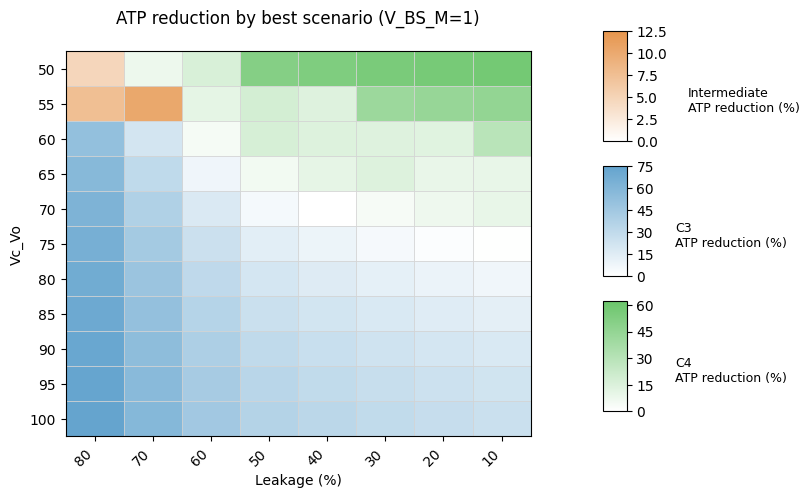

In [16]:
# Heatmap for V_BS_M = 1.0
mask, stacked, summary_df = heatmap_and_summary_noagg(
     structured_C3_leakage, structured_variable_leakage, structured_C4_leakage,
     v_ratio=1, mode="both", show_plot=True, print_table=True, 
        vmin_intermediate=0, vmax_intermediate=12.5,
        vmin_c3=0, vmax_c3=75,
        vmin_c4=0, vmax_c4=62,
        figsize=(6, 5))

#plt.savefig("../Images/heatmap_V_BS_M_1.0.svg", format="svg", bbox_inches="tight")


Summary table (lowest ATP scenario and % difference to closest other):

 Vc_Vo  Leakage (%) ATP_var  ATP_C3  ATP_C4 Best_scenario Pct_diff_closest (%)
  50.0         10.0     NaN 352.323 141.088            C4                60.0%
  50.0         20.0     NaN 351.895 144.896            C4                58.8%
  50.0         30.0     NaN 351.840 149.705            C4                57.5%
  50.0         40.0     NaN 352.168 156.118            C4                55.7%
  50.0         50.0     NaN 352.088 165.570            C4                53.0%
  50.0         60.0     NaN 352.007 181.376            C4                48.5%
  50.0         70.0 223.647 351.927 210.174            C4                 6.0%
  50.0         80.0 293.836 351.559 287.325            C4                 2.2%
  55.0         10.0     NaN 257.916 141.088            C4                45.3%
  55.0         20.0     NaN 257.861 144.896            C4                43.8%
  55.0         30.0     NaN 258.007 149.705            C4 

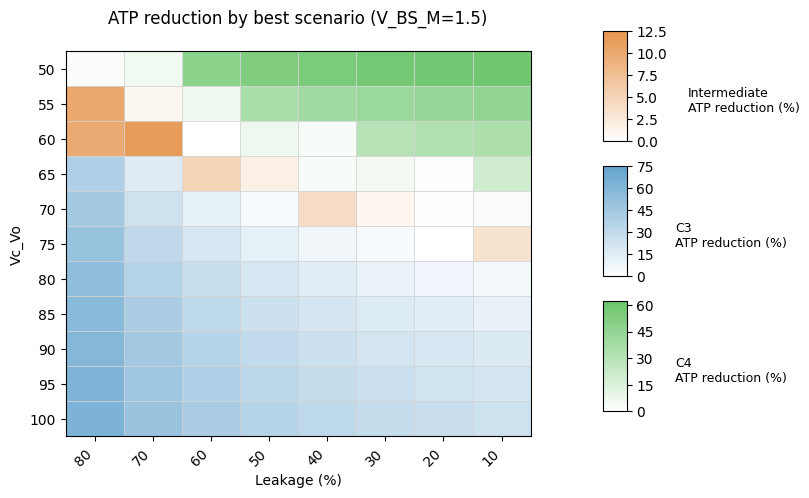

In [17]:
# Heatmap for V_BS_M = 1.5
mask, stacked, summary_df = heatmap_and_summary_noagg(
     structured_C3_leakage, structured_variable_leakage, structured_C4_leakage,
     v_ratio=1.5, mode="both", show_plot=True, print_table=True, 
        vmin_intermediate=0, vmax_intermediate=12.5,
        vmin_c3=0, vmax_c3=75,
        vmin_c4=0, vmax_c4=62,
        figsize=(6, 5))

#plt.savefig("../Images/heatmap_V_BS_M_1.5.svg", format="svg", bbox_inches="tight")


Summary table (lowest ATP scenario and % difference to closest other):

 Vc_Vo  Leakage (%) ATP_var  ATP_C3  ATP_C4 Best_scenario Pct_diff_closest (%)
  50.0         10.0     NaN 353.784 134.683            C4                61.9%
  50.0         20.0     NaN 353.847 140.107            C4                60.4%
  50.0         30.0     NaN 353.973 147.280            C4                58.4%
  50.0         40.0     NaN 353.889 156.243            C4                55.8%
  50.0         50.0     NaN 354.074 167.810            C4                52.6%
  50.0         60.0     NaN 354.103 182.544            C4                48.4%
  50.0         70.0     NaN 354.417 205.356            C4                42.1%
  50.0         80.0     NaN 354.652 247.323            C4                30.3%
  55.0         10.0     NaN 270.641 134.683            C4                50.2%
  55.0         20.0     NaN 270.749 140.107            C4                48.3%
  55.0         30.0     NaN 270.922 147.280            C4 

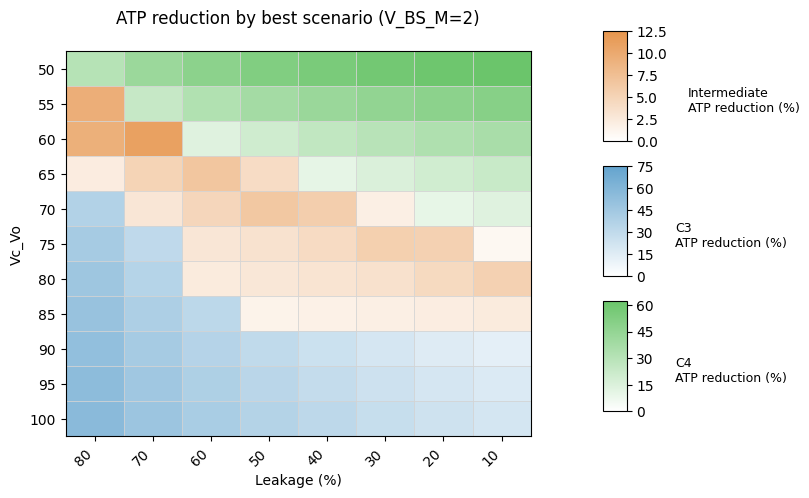

In [18]:
# Heatmap for V_BS_M = 2.0
mask, stacked, summary_df = heatmap_and_summary_noagg(
     structured_C3_leakage, structured_variable_leakage, structured_C4_leakage,
     v_ratio=2, mode="both", show_plot=True, print_table=True, 
        vmin_intermediate=0, vmax_intermediate=12.5,
        vmin_c3=0, vmax_c3=75,
        vmin_c4=0, vmax_c4=62,
        figsize=(6, 5))

#plt.savefig("../Images/heatmap_V_BS_M_2.0.svg", format="svg", bbox_inches="tight")

--- Max Reduced ATP Turnover (%) at V_BS/M = 1.5 ---
C3          : 73.95%
C4          : 59.20%
Intermediate: 15.03%
Pre-C2      : 8.19%
--------------------------------------------------


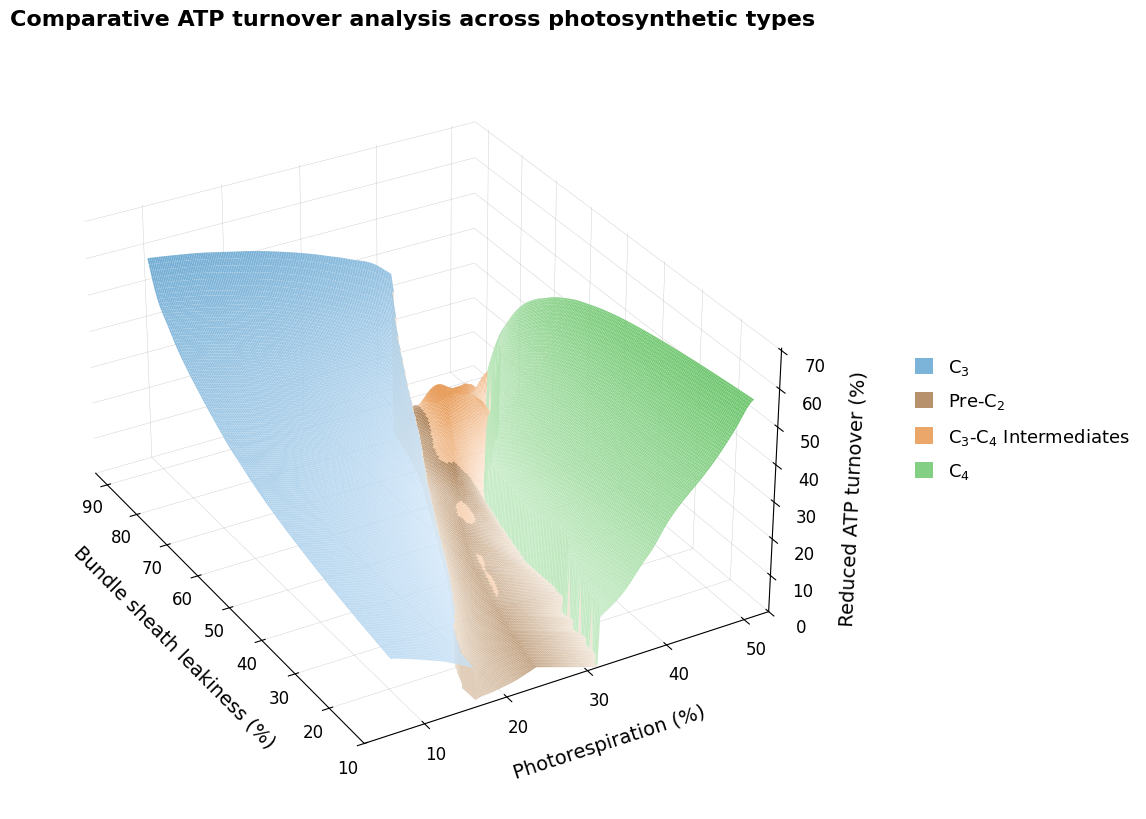

In [19]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

plt.rcParams["mathtext.default"] = "regular"  # upright (non-italic) math text


def nan_gaussian(a, sigma):
    """Gaussian smoothing that ignores NaNs."""
    valid = ~np.isnan(a)
    num = gaussian_filter(np.where(valid, a, 0.0), sigma)
    den = gaussian_filter(valid.astype(float), sigma)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = num / den
    out[~valid] = np.nan
    return out


def plot_smooth_3d_landscape_4cat_clean(
    df_c3,
    df_var,
    df_c4,
    v_ratio,
    output_svg="../Images/landscape_3d_4cat_clean.svg",
    n_grid=200,
    smooth_sigma=2.0,
    elev=28,
    azim=145,
    leak_max_plot=82,         
    leak_axis_max=94,         
    legend_position="right",  
    title="Comparative ATP turnover analysis across photosynthetic types",
):
    def prep_df(df):
        sub = df[
            np.isclose(df["V_BS_M"].astype(float), float(v_ratio), atol=1e-8)
        ].copy()
        sub = sub[(sub["Leakage (%)"] < 91) & (sub["Vc_Vo"] < 95)]
        sub["_ATP"] = sub["ATP M"].astype(float) + sub["ATP BS"].astype(float)
        return sub

    c3_sub = prep_df(df_c3)
    c4_sub = prep_df(df_c4)
    var_sub = prep_df(df_var)

    int_sub = var_sub[
        var_sub["Photosynthesis"].isin(["C3_C4_Type_I", "C3_C4_Type_II"])
    ]
    unid_sub = var_sub[var_sub["Photosynthesis"] == "Unidentified"]

    leak_lo = c3_sub["Leakage (%)"].min()
    grid_leak = np.linspace(leak_lo, c3_sub["Leakage (%)"].max(), n_grid)
    grid_vcv = np.linspace(c3_sub["Vc_Vo"].min(), c3_sub["Vc_Vo"].max(), n_grid)
    L_mesh, V_mesh = np.meshgrid(grid_leak, grid_vcv)
    Y_mesh = 100 - V_mesh  # Photorespiration (%)

    def get_smooth_atp(df):
        if df.empty:
            return np.full(L_mesh.shape, np.nan)
        z = griddata(
            (df["Leakage (%)"], df["Vc_Vo"]),
            df["_ATP"],
            (L_mesh, V_mesh),
            method="linear",
        )
        return nan_gaussian(z, smooth_sigma) if smooth_sigma > 0 else z

    atp_c3 = get_smooth_atp(c3_sub)
    atp_c4 = get_smooth_atp(c4_sub)
    atp_int = get_smooth_atp(int_sub)
    atp_unid = get_smooth_atp(unid_sub)

    # Global optimum and best category per grid cell
    stacked_all = np.stack([atp_c3, atp_c4, atp_int, atp_unid], axis=0)
    all_nan = np.isnan(stacked_all).all(axis=0)
    best_idx = np.argmin(
        np.where(np.isnan(stacked_all), np.inf, stacked_all), axis=0
    )
    z_min = np.nanmin(np.where(all_nan, 0, stacked_all), axis=0)

    # C3/C4 winners are compared to the worse of C3/C4; the others to the better
    sorted_c3_c4 = np.sort(np.stack([atp_c3, atp_c4], axis=0), axis=0)
    z_comparison = np.where(best_idx <= 1, sorted_c3_c4[1], sorted_c3_c4[0])

    with np.errstate(divide="ignore", invalid="ignore"):
        Z_height = (z_comparison - z_min) / z_comparison * 100
    Z_height[all_nan] = np.nan

    cats = [
        (0, "C3", "$C_3$",
         LinearSegmentedColormap.from_list("c3", ["#dceeff", "#64a4ce"]), 75),
        (1, "C4", "$C_4$",
         LinearSegmentedColormap.from_list("c4", ["#e2f7e2", "#6bc56b"]), 62),
        (2, "Intermediate", "$C_3$-$C_4$ Intermediates",
         LinearSegmentedColormap.from_list("int", ["#ffeada", "#e6954d"]), 15),
        (3, "Pre-C2", "Pre-$C_2$",
         LinearSegmentedColormap.from_list("unid", ["#f2e6d8", "#a87c51"]), 15),
    ]

    norms = {}
    for idx, _, _, _, default in cats:
        m = (best_idx == idx) & ~np.isnan(Z_height)
        vmax = np.nanmax(Z_height[m]) if m.any() else default
        norms[idx] = Normalize(0, max(vmax, 1e-9))

    colors = np.zeros(Z_height.shape + (4,))
    Z_safe = np.nan_to_num(Z_height, nan=0.0)
    for idx, _, _, cmap, _ in cats:
        sel = best_idx == idx
        colors[sel] = cmap(norms[idx](Z_safe[sel]))
    colors[np.isnan(Z_height)] = (1, 1, 1, 0)

    print(f"--- Max Reduced ATP Turnover (%) at V_BS/M = {v_ratio} ---")
    for idx, name, _, _, _ in cats:
        m = (best_idx == idx) & ~np.isnan(Z_height)
        if m.any():
            print(f"{name:12}: {np.nanmax(Z_height[m]):.2f}%")
        else:
            print(f"{name:12}: No regions found where this type is optimal.")
    print("-" * 50)

    plot_cols = grid_leak <= leak_max_plot
    L_plot = L_mesh[:, plot_cols]
    Y_plot = Y_mesh[:, plot_cols]
    Z_plot = Z_height[:, plot_cols]
    colors_plot = colors[:, plot_cols, :]

    # Plot
    fig = plt.figure(figsize=(14, 10))
    ax = fig.add_subplot(111, projection="3d")

    ax.plot_surface(
        L_plot, Y_plot, Z_plot,
        facecolors=colors_plot,
        shade=False,
        linewidth=0,
        antialiased=True,
        rcount=n_grid,
        ccount=n_grid,
        rasterized=True,
    )

    ax.set_xlim(leak_lo, leak_axis_max)  
    ax.set_zlim(0, np.nanmax(Z_plot) * 1.05)
    ax.invert_yaxis()
    ax.view_init(elev=30, azim=150)
    ax.set_box_aspect((1.25, 1.0, 0.65))

    ax.set_title(title, fontsize=16, fontweight="bold", pad=10)

    ax.set_xlabel("Bundle sheath leakiness (%)", fontsize=14, labelpad=14)
    ax.set_ylabel("Photorespiration (%)", fontsize=14, labelpad=14)
    ax.set_zlabel("Reduced ATP turnover (%)", fontsize=14, labelpad=10)
    ax.tick_params(axis="both", labelsize=12, pad=3)
    ax.tick_params(axis="z", labelsize=12, pad=5)

    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.pane.fill = False
        axis.pane.set_edgecolor("none")
        axis._axinfo["grid"]["linewidth"] = 0.3
        axis._axinfo["grid"]["color"] = (0.6, 0.6, 0.6, 0.5)

    # C3, Pre-C2, C3-C4 Intermediates, C4
    legend_order = [0, 3, 2, 1]
    cats_by_idx = {c[0]: c for c in cats}
    handles = [
        Patch(
            facecolor=cats_by_idx[i][3](0.8),
            edgecolor="none",
            label=cats_by_idx[i][2],
        )
        for i in legend_order
    ]
    if legend_position == "bottom":
        fig.legend(
            handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.02),
            ncol=len(handles), frameon=False, fontsize=13,
            handlelength=1.0, handleheight=1.0, columnspacing=2.0,
        )
    else:
        fig.legend(
            handles=handles, loc="center left", bbox_to_anchor=(0.86, 0.5),
            frameon=False, fontsize=13, handlelength=1.0, handleheight=1.0,
            labelspacing=0.8,
        )

    fig.savefig(output_svg, format="svg", bbox_inches="tight", dpi=300)
    plt.show()


df_var_fg = pd.read_csv(
    "../Datasets/structured_variable_leakage_fine_grained.csv"
)
df_c3_fg = pd.read_csv("../Datasets/structured_C3_leakage_fine_grained.csv")
df_c4_fg = pd.read_csv("../Datasets/structured_C4_leakage_fine_grained.csv")

plot_smooth_3d_landscape_4cat_clean(
    df_c3_fg, df_var_fg, df_c4_fg, v_ratio=1.5
)

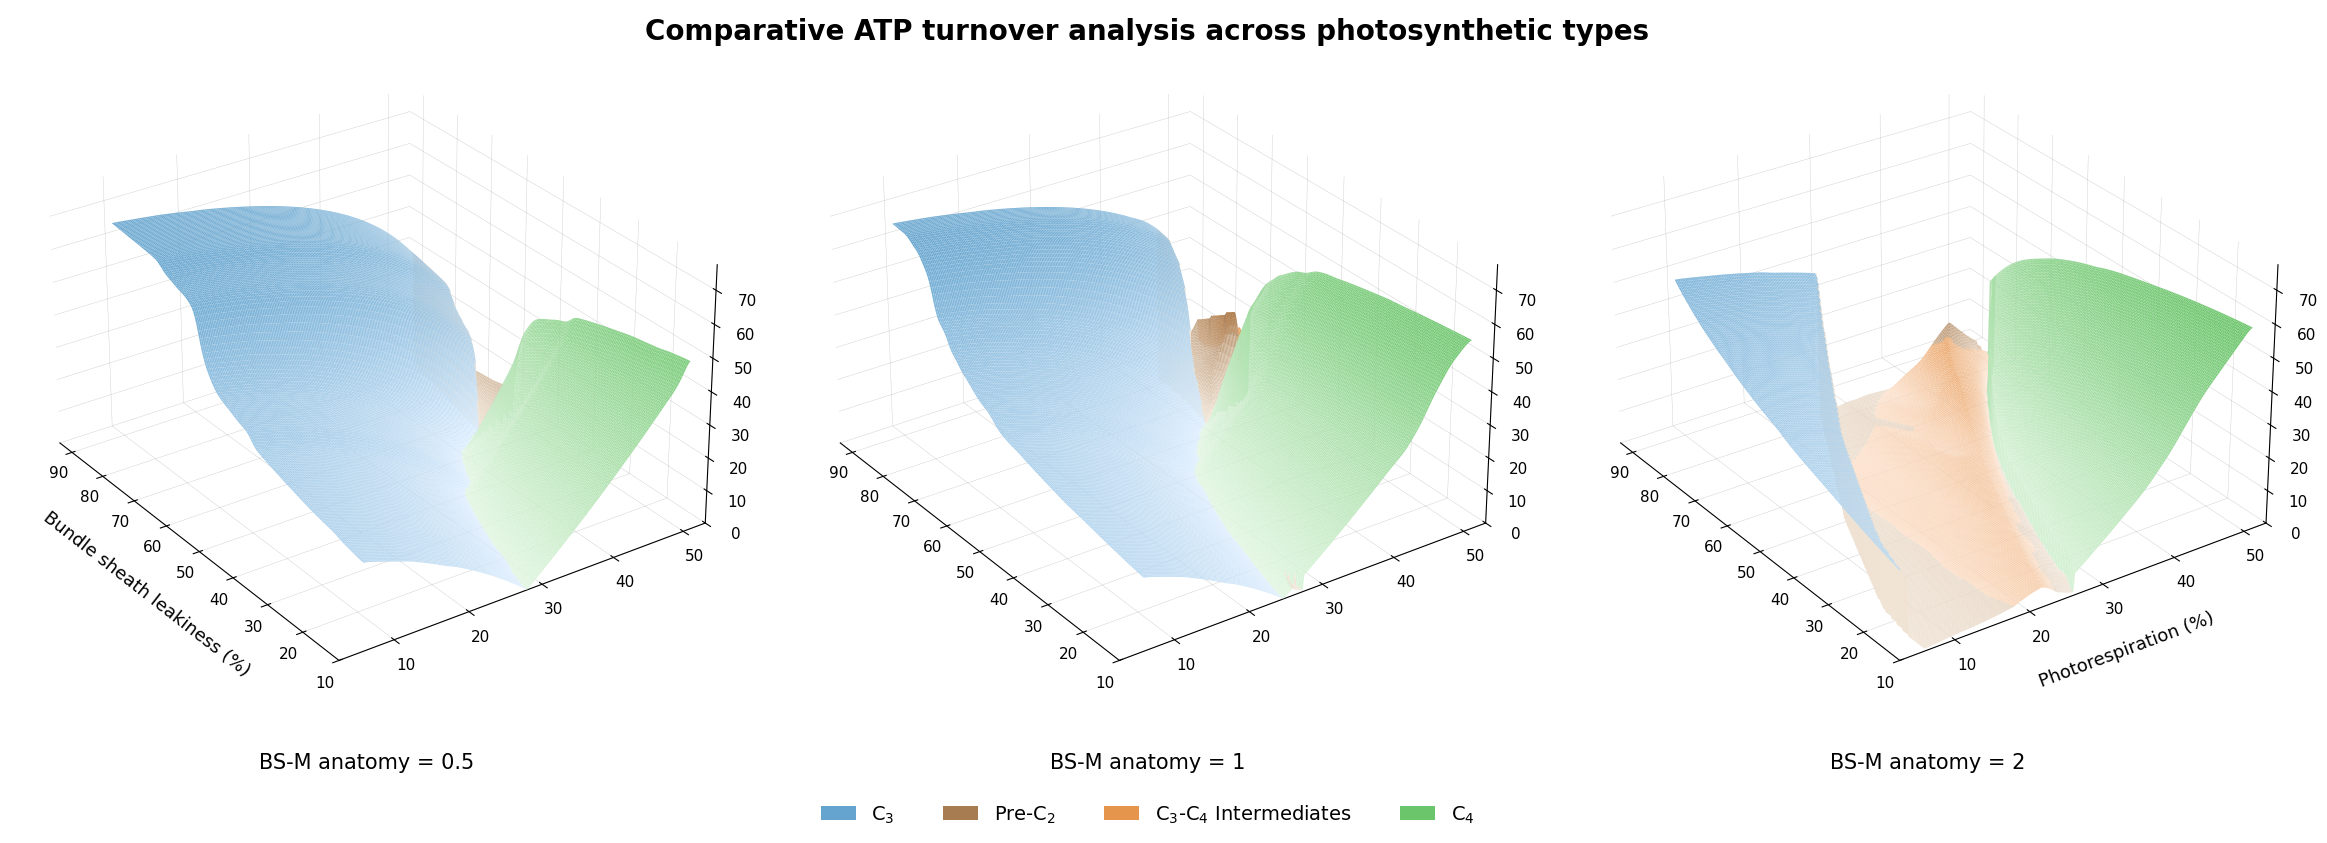

In [20]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.patches import Patch
from scipy.interpolate import griddata
from scipy.ndimage import gaussian_filter

plt.rcParams["mathtext.default"] = "regular"  

CATS = [
    (0, "$C_3$", LinearSegmentedColormap.from_list("c3", ["#dceeff", "#64a4ce"])),
    (1, "$C_4$", LinearSegmentedColormap.from_list("c4", ["#e2f7e2", "#6bc56b"])),
    (2, "$C_3$-$C_4$ Intermediates",
     LinearSegmentedColormap.from_list("int", ["#ffeada", "#e6954d"])),
    (3, "Pre-$C_2$",
     LinearSegmentedColormap.from_list("unid", ["#f2e6d8", "#a87c51"])),
]


def nan_gaussian(a, sigma):
    """Gaussian smoothing that ignores NaNs."""
    valid = ~np.isnan(a)
    num = gaussian_filter(np.where(valid, a, 0.0), sigma)
    den = gaussian_filter(valid.astype(float), sigma)
    with np.errstate(invalid="ignore", divide="ignore"):
        out = num / den
    out[~valid] = np.nan
    return out


def compute_landscape(df_c3, df_var, df_c4, v_ratio, n_grid=200, smooth_sigma=2.0):
    def prep_df(df):
        sub = df[
            np.isclose(df["V_BS_M"].astype(float), float(v_ratio), atol=1e-8)
        ].copy()
        sub = sub[(sub["Leakage (%)"] < 91) & (sub["Vc_Vo"] < 100)]
        sub["_ATP"] = sub["ATP M"].astype(float) + sub["ATP BS"].astype(float)
        return sub

    c3_sub, c4_sub, var_sub = prep_df(df_c3), prep_df(df_c4), prep_df(df_var)
    int_sub = var_sub[
        var_sub["Photosynthesis"].isin(["C3_C4_Type_I", "C3_C4_Type_II"])
    ]
    unid_sub = var_sub[var_sub["Photosynthesis"] == "Unidentified"]

    grid_leak = np.linspace(
        c3_sub["Leakage (%)"].min(), c3_sub["Leakage (%)"].max(), n_grid
    )
    grid_vcv = np.linspace(c3_sub["Vc_Vo"].min(), c3_sub["Vc_Vo"].max(), n_grid)
    L_mesh, V_mesh = np.meshgrid(grid_leak, grid_vcv)
    Y_mesh = 100 - V_mesh  # Photorespiration (%)

    def get_smooth_atp(df):
        if df.empty:
            return np.full(L_mesh.shape, np.nan)
        z = griddata(
            (df["Leakage (%)"], df["Vc_Vo"]),
            df["_ATP"],
            (L_mesh, V_mesh),
            method="linear",
        )
        return nan_gaussian(z, smooth_sigma) if smooth_sigma > 0 else z

    stacked = np.stack(
        [get_smooth_atp(d) for d in (c3_sub, c4_sub, int_sub, unid_sub)], axis=0
    )
    all_nan = np.isnan(stacked).all(axis=0)
    best_idx = np.argmin(np.where(np.isnan(stacked), np.inf, stacked), axis=0)
    z_min = np.nanmin(np.where(all_nan, 0, stacked), axis=0)

    # C3/C4 winners vs. the worse of C3/C4; the others vs. the better
    sorted_c3_c4 = np.sort(stacked[:2], axis=0)
    z_comp = np.where(best_idx <= 1, sorted_c3_c4[1], sorted_c3_c4[0])

    with np.errstate(divide="ignore", invalid="ignore"):
        Z = (z_comp - z_min) / z_comp * 100
    Z[all_nan] = np.nan

    return L_mesh, Y_mesh, Z, best_idx


def plot_landscape_comparison(
    df_c3,
    df_var,
    df_c4,
    v_ratios=(0.5, 1.0, 2.0),
    output_svg="../Images/landscape_3d_comparison.svg",
    n_grid=200,
    smooth_sigma=2.0,
    elev=28,
    azim=145,
    leak_max_plot=82,   
    leak_axis_max=94,  
):
    results = [
        compute_landscape(df_c3, df_var, df_c4, v, n_grid, smooth_sigma)
        for v in v_ratios
    ]

    norms = {}
    for idx, _, _ in CATS:
        vals = [Z[(best == idx) & ~np.isnan(Z)] for _, _, Z, best in results]
        vmax = max((v.max() for v in vals if v.size), default=1.0)
        norms[idx] = Normalize(0, max(vmax, 1e-9))

    z_top = max(
        np.nanmax(Z[:, L[0] <= leak_max_plot]) for L, _, Z, _ in results
    ) * 1.05

    fig = plt.figure(figsize=(24, 8.5))
    n_panels = len(v_ratios)

    for k, (v, (L, Y, Z, best)) in enumerate(zip(v_ratios, results)):
        ax = fig.add_subplot(1, n_panels, k + 1, projection="3d")

        colors = np.zeros(Z.shape + (4,))
        Z_safe = np.nan_to_num(Z, nan=0.0)
        for idx, _, cmap in CATS:
            sel = best == idx
            colors[sel] = cmap(norms[idx](Z_safe[sel]))
        colors[np.isnan(Z)] = (1, 1, 1, 0)

        cols = L[0] <= leak_max_plot
        ax.plot_surface(
            L[:, cols], Y[:, cols], Z[:, cols],
            facecolors=colors[:, cols, :],
            shade=False,
            linewidth=0,
            antialiased=True,
            rcount=n_grid,
            ccount=n_grid,
            rasterized=True,
        )

        ax.set_xlim(L.min(), leak_axis_max)  
        ax.set_zlim(0, z_top)
        ax.invert_yaxis()
        ax.view_init(elev=elev, azim=azim)
        ax.set_box_aspect((1.15, 1.0, 0.65))

        if k == 0:
            ax.set_xlabel("Bundle sheath leakiness (%)", fontsize=13, labelpad=12)
        if k == n_panels - 1:
            ax.set_ylabel("Photorespiration (%)", fontsize=13, labelpad=12)
            ax.set_zlabel("Reduced ATP turnover (%)", fontsize=13, labelpad=8)

        ax.tick_params(axis="both", labelsize=11, pad=2)
        ax.tick_params(axis="z", labelsize=11, pad=4)

        for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
            axis.pane.fill = False
            axis.pane.set_edgecolor("none")
            axis._axinfo["grid"]["linewidth"] = 0.3
            axis._axinfo["grid"]["color"] = (0.6, 0.6, 0.6, 0.5)

        # Caption below each panel
        ax.text2D(
            0.5, -0.04, f"BS-M anatomy = {v:g}",
            transform=ax.transAxes, ha="center", va="top", fontsize=15,
        )

    legend_order = [0, 3, 2, 1]  # C3, Pre-C2, Intermediates, C4
    handles = [
        Patch(facecolor=CATS[i][2](1.0), edgecolor="none", label=CATS[i][1])
        for i in legend_order
    ]
    fig.legend(
        handles=handles, loc="lower center", ncol=len(CATS),
        fontsize=14, frameon=False, handlelength=1.8, columnspacing=2.5,
        bbox_to_anchor=(0.5, 0.0),
    )

    fig.suptitle(
        "Comparative ATP turnover analysis across photosynthetic types",
        fontsize=20, fontweight="bold", y=0.97,
    )
    fig.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.14, wspace=0.05)

    fig.savefig(output_svg, format="svg", bbox_inches="tight", dpi=300)
    plt.show()


df_var_fg = pd.read_csv(
    "../Datasets/structured_variable_leakage_fine_grained.csv"
)
df_c3_fg = pd.read_csv("../Datasets/structured_C3_leakage_fine_grained.csv")
df_c4_fg = pd.read_csv("../Datasets/structured_C4_leakage_fine_grained.csv")

plot_landscape_comparison(df_c3_fg, df_var_fg, df_c4_fg)

## 6. Visualization: Quantum Yield Heatmaps
Compare Quantum Yield improvement between scenarios.

In [21]:
def quantum_yield_heatmap_and_summary(
        df_c3, df_var, df_c4,
        v_ratio,
        leakage_col="Leakage (%)", vcv_col="Vc_Vo",
        photosyn_col="Photosynthesis",
        v_ratio_col="V_BS_M",
        mode="both", tol=1e-8,
        figsize=(10, 6), show_plot=True,
        annot_fmt="{:.1f}%", annot_fontsize=10,
        print_table=True,
        vmin_intermediate=None, vmax_intermediate=None,
        vmin_c3=None, vmax_c3=None,
        vmin_c4=None, vmax_c4=None):
    """
    Build annotated heatmap with three different color gradients showing Quantum Yield increase (%)
    for intermediate, C3, and C4 scenarios in a single plot.
    
    Parameters:
      vmin_intermediate, vmax_intermediate : float, optional
          Lower and upper bounds for the color scale of Intermediate QY percentage increase.
      vmin_c3, vmax_c3 : float, optional
          Lower and upper bounds for the color scale of C3 QY percentage increase.
      vmin_c4, vmax_c4 : float, optional
          Lower and upper bounds for the color scale of C4 QY percentage increase.
          If None, uses the data range for each scenario.
    """

    # --- 1) Filter for V_BS_M and compute Quantum Yield per-row ---
    def select_vratio(df):
        if v_ratio_col not in df.columns:
            raise KeyError(f"'{v_ratio_col}' not found in dataframe")
        
        # Filter by V_BS_M
        sub = df[np.isclose(df[v_ratio_col].astype(float), float(v_ratio), atol=tol)].copy()
        
        # Filter out Leakage 90 and 100
        if leakage_col in sub.columns:
            sub = sub[~sub[leakage_col].isin([90, 100])]
            
        return sub

    df_c3_sel = select_vratio(df_c3)
    df_c4_sel = select_vratio(df_c4)
    df_var_sel = select_vratio(df_var)

    # Columns required for Quantum Yield
    req_cols = ["Carbon Uptake", "Light Mesophyll", "Light Bundle Sheath"]

    for name, df in (("C3", df_c3_sel), ("VAR", df_var_sel), ("C4", df_c4_sel)):
        for col in req_cols:
            if col not in df.columns:
                raise KeyError(f"Column '{col}' missing in {name} dataset")
        
        # Calculate Quantum Yield = Carbon Uptake / Total Light
        total_light = df["Light Mesophyll"].astype(float) + df["Light Bundle Sheath"].astype(float)
        # Handle division by zero if necessary, though light usually > 0
        df["_Quantum_Yield"] = df["Carbon Uptake"].astype(float) / total_light

    # Restrict variable dataset to the intermediate classes
    if photosyn_col not in df_var_sel.columns:
        raise KeyError(f"'{photosyn_col}' not in variable dataset")
    allowed = {"C3_C4_Type_I", "C3_C4_Type_II"}
    df_var_inter = df_var_sel[df_var_sel[photosyn_col].astype(str).isin(allowed)].copy()

    # --- Build mapping from (leak, vcv) -> Quantum Yield, ensure uniqueness ---
    def mapping_from_df(df, df_name):
        if df.empty:
            return {}
        for col in (leakage_col, vcv_col):
            if col not in df.columns:
                raise KeyError(f"'{col}' missing from {df_name}")
        keys = list(zip(df[leakage_col].astype(float), df[vcv_col].astype(float)))
        dupes = [k for k, c in Counter(keys).items() if c > 1]
        if dupes:
            raise ValueError(f"Dataset '{df_name}' contains duplicate (Leakage, Vc_Vo) pairs: {dupes}. "
                             "This function assumes unique pairs (no aggregation).")
        return {k: float(v) for k, v in zip(keys, df["_Quantum_Yield"].values)}

    map_c3 = mapping_from_df(df_c3_sel, "C3")
    map_c4 = mapping_from_df(df_c4_sel, "C4")
    map_var = mapping_from_df(df_var_inter, "Variable (C3-C4 intermediates)")

    # --- Build coordinate grid (union of keys) and DataFrames ---
    all_keys = sorted(set(list(map_c3.keys()) + list(map_c4.keys()) + list(map_var.keys())),
                      key=lambda x: (x[1], x[0]))
    if not all_keys:
        raise ValueError(f"No (Leakage, Vc_Vo) pairs found in the filtered datasets for V_BS_M={v_ratio}")

    leaks = sorted({k[0] for k in all_keys})
    vcvs = sorted({k[1] for k in all_keys})

    grid_c3 = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)
    grid_c4 = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)
    grid_var = pd.DataFrame(index=vcvs, columns=leaks, dtype=float)

    for (l, v) in all_keys:
        grid_c3.at[v, l] = map_c3.get((l, v), np.nan)
        grid_c4.at[v, l] = map_c4.get((l, v), np.nan)
        grid_var.at[v, l] = map_var.get((l, v), np.nan)

    rows = []
    for (leak, vcv) in sorted({(k[0], k[1]) for k in all_keys}, key=lambda x: (x[1], x[0])):
        qy_var = grid_var.at[vcv, leak]
        qy_c3 = grid_c3.at[vcv, leak]
        qy_c4 = grid_c4.at[vcv, leak]

        # Collect available scenarios (exclude NaNs)
        vals = {}
        if not (qy_var is None or (isinstance(qy_var, float) and np.isnan(qy_var))):
            vals["Intermediate"] = float(qy_var)
        if not (qy_c3 is None or (isinstance(qy_c3, float) and np.isnan(qy_c3))):
            vals["C3"] = float(qy_c3)
        if not (qy_c4 is None or (isinstance(qy_c4, float) and np.isnan(qy_c4))):
            vals["C4"] = float(qy_c4)

        if len(vals) == 0:
            best = None
            pct_diff_closest = np.nan
        else:
            # HIGHEST is best for Quantum Yield
            max_val = max(vals.values())
            best_scenarios = [k for k, vv in vals.items() if vv == max_val]
            best = "|".join(best_scenarios)

            other_vals = [vv for k, vv in vals.items() if vv != max_val]
            if len(other_vals) == 0:
                pct_diff_closest = 0.0 if len(best_scenarios) > 1 else np.nan
            else:
                # Compare to the second highest
                max_other = max(other_vals)
                if np.isclose(max_other, 0.0):
                    pct_diff_closest = np.nan
                else:
                    # Percentage INCREASE relative to the second best
                    pct_diff_closest = round((max_val - max_other) / max_other * 100.0, 1)

        rows.append({
            vcv_col: vcv,
            leakage_col: leak,
            "QY_var": qy_var,
            "QY_C3": qy_c3,
            "QY_C4": qy_c4,
            "Best_scenario": best,
            "Pct_diff_closest (%)": pct_diff_closest
        })

    summary_df = pd.DataFrame(rows, columns=[vcv_col, leakage_col, "QY_var", "QY_C3", "QY_C4", "Best_scenario", "Pct_diff_closest (%)"])
    summary_df = summary_df.sort_values([vcv_col, leakage_col], ascending=[True, True]).reset_index(drop=True)

    if show_plot:
        fig, ax = plt.subplots(figsize=figsize)
        
        # Determine vmin/vmax for each scenario
        intermediate_pcts = summary_df[summary_df["Best_scenario"].str.contains("Intermediate", na=False)]["Pct_diff_closest (%)"].dropna()
        c3_pcts = summary_df[summary_df["Best_scenario"] == "C3"]["Pct_diff_closest (%)"].dropna()
        c4_pcts = summary_df[summary_df["Best_scenario"] == "C4"]["Pct_diff_closest (%)"].dropna()
        
        # Helper to safely get min/max
        def safe_min_max(series, default_min=0, default_max=10):
            if len(series) == 0:
                return default_min, default_max
            return series.min(), series.max()

        i_min, i_max = safe_min_max(intermediate_pcts)
        c3_min, c3_max = safe_min_max(c3_pcts)
        c4_min, c4_max = safe_min_max(c4_pcts)
        
        # Set defaults if not provided - use specific min/max for each
        if vmin_intermediate is None:
            vmin_intermediate = i_min
        if vmax_intermediate is None:
            vmax_intermediate = i_max
            
        if vmin_c3 is None:
            vmin_c3 = c3_min
        if vmax_c3 is None:
            vmax_c3 = c3_max
            
        if vmin_c4 is None:
            vmin_c4 = c4_min
        if vmax_c4 is None:
            vmax_c4 = c4_max
        
        # Create three colormaps
        cmap_intermediate = LinearSegmentedColormap.from_list("intermediate", ["#ffffff", "#e6954dff"])
        cmap_c3 = LinearSegmentedColormap.from_list("c3", ["#ffffff", "#64a4ceff"])
        cmap_c4 = LinearSegmentedColormap.from_list("c4", ["#ffffff", "#6bc56bff"])
        
        # Plot each cell individually based on best scenario
        for _, row in summary_df.iterrows():
            vcv_val = row[vcv_col]
            leak_val = row[leakage_col]
            best_scenario = row["Best_scenario"]
            pct_diff = row["Pct_diff_closest (%)"]
            
            if pd.isna(pct_diff) or best_scenario is None:
                continue
            
            if vcv_val in vcvs and leak_val in leaks:
                i = vcvs.index(vcv_val)
                j = leaks.index(leak_val)
                
                # Select vmin/vmax and colormap based on best scenario
                if "Intermediate" in best_scenario:
                    vmin_use = vmin_intermediate
                    vmax_use = vmax_intermediate
                    cmap_use = cmap_intermediate
                elif best_scenario == "C3":
                    vmin_use = vmin_c3
                    vmax_use = vmax_c3
                    cmap_use = cmap_c3
                elif best_scenario == "C4":
                    vmin_use = vmin_c4
                    vmax_use = vmax_c4
                    cmap_use = cmap_c4
                else:
                    color = 'white'
                    ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, 
                                              facecolor=color, 
                                              edgecolor='lightgray', linewidth=0.5))
                    continue
                
                # Normalize percentage to [0, 1] for colormap
                norm_pct = (pct_diff - vmin_use) / (vmax_use - vmin_use) if vmax_use > vmin_use else 0
                norm_pct = np.clip(norm_pct, 0, 1)
                
                color = cmap_use(norm_pct)
                
                # Draw the cell
                ax.add_patch(plt.Rectangle((j, i), 1, 1, fill=True, 
                                          facecolor=color, 
                                          edgecolor='lightgray', linewidth=0.5))
        
        # Set up axis
        ax.set_xlim(0, len(leaks))
        ax.set_ylim(0, len(vcvs))
        ax.set_xticks(np.arange(len(leaks)) + 0.5)
        ax.set_yticks(np.arange(len(vcvs)) + 0.5)
        ax.set_xticklabels(
            [f"{l:.1f}" if abs(l - round(l)) > 1e-6 else f"{int(round(l))}" for l in leaks],
            rotation=45, ha='right'
        )
        ax.set_yticklabels(
            [f"{v:.2f}" if abs(v - round(v)) > 1e-6 else f"{int(round(v))}" for v in vcvs],
            rotation=0
        )
        
        ax.set_xlabel(leakage_col)
        ax.set_ylabel(vcv_col)
        title_mode = "AND" if mode == "both" else "OR"
        ax.set_title(f"Quantum Yield increase by best scenario (V_BS_M={v_ratio})", pad=20)
        
        ax.invert_xaxis()
        ax.invert_yaxis()
        
        # Create three colorbars
        from matplotlib.cm import ScalarMappable
        from matplotlib.colorbar import Colorbar
        
        # Position for colorbars (to the right of main plot)
        cbar_x = 1.02
        cbar_width = 0.04
        cbar_height = 0.22  # Increased from 0.15
        cbar_spacing = 0.05
        
        # Starting y position for top colorbar
        cbar_y_start = 0.70
        
        # Intermediate colorbar
        cax1 = fig.add_axes([cbar_x, cbar_y_start, cbar_width, cbar_height])
        sm1 = ScalarMappable(cmap=cmap_intermediate, norm=plt.Normalize(vmin=vmin_intermediate, vmax=vmax_intermediate))
        sm1.set_array([])
        cbar1 = plt.colorbar(sm1, cax=cax1)
        cbar1.locator = plt.MaxNLocator(nbins=5)  # More tick marks
        cbar1.update_ticks()
        cbar1.set_label('Intermediate\nQY increase (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        # C3 colorbar
        cax2 = fig.add_axes([cbar_x, cbar_y_start - cbar_height - cbar_spacing, cbar_width, cbar_height])
        sm2 = ScalarMappable(cmap=cmap_c3, norm=plt.Normalize(vmin=vmin_c3, vmax=vmax_c3))
        sm2.set_array([])
        cbar2 = plt.colorbar(sm2, cax=cax2)
        cbar2.locator = plt.MaxNLocator(nbins=5)  # More tick marks
        cbar2.update_ticks()
        cbar2.set_label('C3\nQY increase (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        # C4 colorbar
        cax3 = fig.add_axes([cbar_x, cbar_y_start - 2*(cbar_height + cbar_spacing), cbar_width, cbar_height])
        sm3 = ScalarMappable(cmap=cmap_c4, norm=plt.Normalize(vmin=vmin_c4, vmax=vmax_c4))
        sm3.set_array([])
        cbar3 = plt.colorbar(sm3, cax=cax3)
        cbar3.locator = plt.MaxNLocator(nbins=5)  # More tick marks
        cbar3.update_ticks()
        cbar3.set_label('C4\nQY increase (%)', fontsize=9, rotation=0, 
                       labelpad=15, ha='left')
        
        #plt.savefig(f"Images/biomass_heatmap_V_BS_M_{v_ratio}_mode_{mode}.svg", 
        #        format='svg', 
        #        bbox_inches='tight', 
        #        dpi=300)


    if mode == "both":
        # Variable is better if it is HIGHER than both
        raw_mask = (grid_var > grid_c3) & (grid_var > grid_c4)
    elif mode == "either":
        # Variable is better if it is HIGHER than either
        raw_mask = (grid_var > grid_c3) | (grid_var > grid_c4)
    else:
        raise ValueError("mode must be 'both' or 'either'")

    missing = grid_var.isna() | grid_c3.isna() | grid_c4.isna()
    mask = raw_mask & (~missing)
    
    # Calculate percentage difference for the grid (Intermediate vs others)
    # Compare Intermediate to the BEST of the others
    max_other_vals = pd.DataFrame(np.maximum(grid_c3.values, grid_c4.values),
                                  index=vcvs, columns=leaks)
    
    # (Intermediate - Max_Other) / Max_Other
    pct_grid = (grid_var - max_other_vals) / max_other_vals * 100.0
    pct_grid = pct_grid.where(np.isfinite(pct_grid), np.nan)
    pct_grid_masked = pct_grid.where(mask, np.nan)

    s_var = grid_var.stack().rename("QY_var")
    s_c3 = grid_c3.stack().rename("QY_C3")
    s_c4 = grid_c4.stack().rename("QY_C4")
    s_mask = mask.stack().rename("Var_better")
    s_pct = pct_grid_masked.stack().rename("Pct_higher")

    combined = pd.concat([s_var, s_c3, s_c4, s_mask, s_pct], axis=1).reset_index()
    if combined.shape[1] >= 2:
        vcv_col_current = combined.columns[0]
        leak_col_current = combined.columns[1]
        combined = combined.rename(columns={vcv_col_current: vcv_col, leak_col_current: leakage_col})
        stacked = combined.set_index([leakage_col, vcv_col])

    display_df = summary_df.copy()
    display_df["QY_var"] = display_df["QY_var"].map(lambda x: f"{x:.4f}" if (not pd.isna(x)) else "NaN")
    display_df["QY_C3"] = display_df["QY_C3"].map(lambda x: f"{x:.4f}" if (not pd.isna(x)) else "NaN")
    display_df["QY_C4"] = display_df["QY_C4"].map(lambda x: f"{x:.4f}" if (not pd.isna(x)) else "NaN")
    display_df["Pct_diff_closest (%)"] = display_df["Pct_diff_closest (%)"].map(lambda x: f"{x:.1f}%" if (not pd.isna(x)) else "NaN")
    if print_table:
        print("\nSummary table (Highest Quantum Yield scenario and % difference to closest other):\n")
        print(display_df.to_string(index=False))
    
    return mask, stacked, summary_df


Summary table (Highest Quantum Yield scenario and % difference to closest other):

 Vc_Vo  Leakage (%) QY_var  QY_C3  QY_C4 Best_scenario Pct_diff_closest (%)
  50.0         10.0    NaN 0.0227 0.0696            C4               207.0%
  50.0         20.0    NaN 0.0227 0.0685            C4               201.8%
  50.0         30.0    NaN 0.0227 0.0672            C4               196.0%
  50.0         40.0    NaN 0.0227 0.0656            C4               189.0%
  50.0         50.0    NaN 0.0227 0.0635            C4               179.8%
  50.0         60.0    NaN 0.0227 0.0596            C4               162.5%
  50.0         70.0 0.0395 0.0227 0.0533            C4                34.7%
  50.0         80.0 0.0305 0.0227 0.0403            C4                32.1%
  55.0         10.0    NaN 0.0308 0.0696            C4               126.1%
  55.0         20.0    NaN 0.0308 0.0685            C4               122.5%
  55.0         30.0    NaN 0.0307 0.0672            C4               118.6%
  55

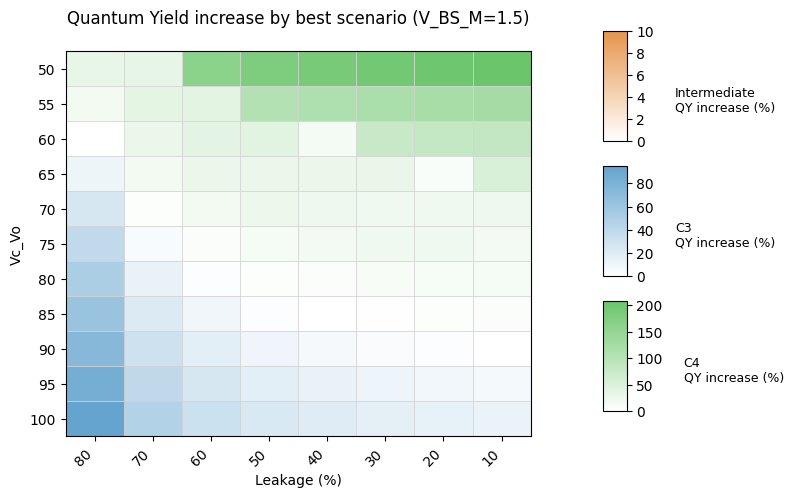

In [22]:
# Quantum Yield Heatmap for V_BS_M = 1.5
mask, stacked, summary_df = quantum_yield_heatmap_and_summary(
     structured_C3_leakage, structured_variable_leakage, structured_C4_leakage,
     v_ratio=1.5, mode="both", show_plot=True, print_table=True, 
        vmin_intermediate=0, vmax_intermediate=None,
        vmin_c3=0, vmax_c3=None,
        vmin_c4=0, vmax_c4=None,
        figsize=(6, 5))